# Predicting FDA Class I Food Recalls from Structured Data — Part 1

Can the structured fields of an FDA food recall, known on the day, predict whether
FDA will classify it as **Class I**, the most serious class? This notebook compares
**logistic regression** with **tuned XGBoost** on openFDA's food enforcement reports, using a
time-based split. Part 2 will model the recall text using NLP on the same splits.

| Phase | What it does |
|---|---|
| 1 | Data preprocessing and leakage audit: decide every column's role and define the time-based splits |
| 2 | Feature engineering (including causal firm history) and univariate feature screening |
| 3 | Model training, hyperparameter tuning, and comparison on validation |
| 4 | Model evaluation: decision-threshold selection, calibration probability check (Brier score), SHAP interpretability, error analysis, and a single held-out test evaluation |

# Phase 1 — Data Preprocessing

In [1]:
import pandas as pd, json

with open("food-enforcement-0001-of-0001.json") as f:
    raw = json.load(f)

df = pd.json_normalize(raw["results"])

df

,status,city,state,country,classification,product_type,event_id,recalling_firm,address_1,address_2,...,recall_number,product_description,product_quantity,reason_for_recall,recall_initiation_date,center_classification_date,report_date,code_info,more_code_info,termination_date
0,Ongoing,N Manchester,IN,United States,Class I,Food,99479,MIDWEST POULTRY SERVC C/O H & LELECTRIC,800 Wabash Rd,,...,H-1230-2026,Grade A White In-shell Chicken eggs packaged i...,"1,589,577 dozen total",Possible Salmonella Enteritidis,20260722,20260812,20260819,Code information is printed on the left or rig...,,NaN
1,Ongoing,Doctor Mora,,Mexico,Not Yet Classified,Food,99453,Taylor Farms de Mexico S. de R.L. de C.V.,Carretera Dr. Mora A San Miguel De Allende Km. 16,Doctor Mora,...,,MARKON BLEND LETT/ROM 80/20 WITH SEP BAGGIES 4...,855 cases,Potential Cyclospora contamination.,20260717,NaN,20260819,MARKON BLEND LETT/ROM 80/20 WITH SEP BAGGIES 4...,,NaN
2,Ongoing,Diamond Bar,CA,United States,Class III,Food,99540,FlavorsandColor.Com,20653 Lycoming St Ste A9,,...,H-1225-2026,"Honeyville YELLOW COLOR 1 GALLON NFI: WATER, ...",80 cases,Undeclared Red #40.,20260728,20260807,20260819,Lot: 60609-8 EXP: 06/08/28,,NaN
3,Ongoing,Venice,FL,United States,Class II,Food,99516,SHEANDRO LLC,13392 Caravaggio Ct,,...,H-1224-2026,"Vodka Tomato Sauce, NET WT. 24 oz / 680g, glas...",76 cases (12/24Oz.),"Label declares cream and cheese, but Milk is n...",20260723,20260807,20260819,Lot Code: LZ1 R169 Expiration Date (s): 06/30/...,,NaN
4,Ongoing,Allentown,PA,United States,Class I,Food,99097,Bazzini LLC,1035 Mill Rd,,...,H-1228-2026,"Dark Chocolate Coconut Almond Bites, 3.17oz, P...","1,382,916 Pieces",Undeclared peanuts,20260523,20260812,20260819,"B15354, B15356, B15357, B15360, B15361, B15363",,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29312,Terminated,El Paso,TX,United States,Class III,Food,98468,"Tipp Distributors, Inc. dba Novamex",500 W Overland Ave Ste 300,N/A,...,H-0545-2026,C2O Coconut Water with Pulp (17.5 oz) 15 Pack ...,"12,000 Cases",The outer cardboard box for the canned coconut...,20260225,20260306,20260318,Expiry 4/3/2027 to 6/5/2027,NaN,20260819
29313,Terminated,Miami,FL,United States,Class II,Food,98732,Galaxy RG Corp,13815 Sw 139th Ct,N/A,...,H-0919-2026,Rollitos de Guava [image] Guava Rolls The Orig...,"7,856 (15-oz) units","Undeclared colors (Yellow #5, Yellow #6, and/o...",20260403,20260609,20260617,Expiration Date: From 04/03/2026 to 05/03/2026...,NaN,20260817
29314,Terminated,Miami,FL,United States,Class II,Food,98732,Galaxy RG Corp,13815 Sw 139th Ct,N/A,...,H-0927-2026,"Tiramisu [image] Cofee Cake The Original, Net ...",221 (30-oz) units,"Undeclared colors (Yellow #5, Yellow #6, and/o...",20260403,20260609,20260617,Expiration Date: From 04/03/2026 to 05/03/2026...,NaN,20260817
29315,Terminated,Miami,FL,United States,Class II,Food,98732,Galaxy RG Corp,13815 Sw 139th Ct,N/A,...,H-0931-2026,Marquesita de Dulceleche [image] Delighted Fla...,877 (16-oz) units,"Undeclared colors (Yellow #5, Yellow #6, and/o...",20260403,20260609,20260617,Expiration Date: From 04/03/2026 to 05/03/2026...,NaN,20260817


In [2]:
print("shape:", df.shape)
print("columns:", sorted(df.columns.tolist()))

# openfda is an empty dict on every record, so json_normalize emits no columns for it
n_openfda = sum(1 for r in raw["results"] if r.get("openfda"))
print(f"\nrecords with non-empty openfda: {n_openfda} / {len(raw['results'])}")

# --- date parsing ---
date_cols = ["recall_initiation_date", "center_classification_date",
             "report_date", "termination_date"]
raw_dates = df[date_cols].copy()

for col in date_cols:
    df[col] = pd.to_datetime(df[col], format="%Y%m%d", errors="coerce")

print("\n--- date parse audit ---")
for col in date_cols:
    n_null = df[col].isna().sum()
    print(f"{col:30s} unparsed={n_null:5d} ({n_null/len(df):6.2%})  "
          f"{df[col].min().date()} -> {df[col].max().date()}")

# errors="coerce" hides bad values as NaT, so print the ones that were non-null pre-parse
print("\n--- values that failed to parse (were present, became NaT) ---")
for col in date_cols:
    bad = raw_dates.loc[df[col].isna() & raw_dates[col].notna(), col]
    if len(bad):
        print(f"{col}: {bad.to_dict() if len(bad) < 20 else bad.head(5).tolist()}")
print("termination_date unparsed since not reported yet, not error")

print("\n--- date ordering violations ---")
print("initiation > report_date:           ",
      (df["recall_initiation_date"] > df["report_date"]).sum())
print("initiation > center_classification: ",
      (df["recall_initiation_date"] > df["center_classification_date"]).sum())

# the dataset window is defined by report_date; earlier initiation dates are backdated
print("\n--- coverage window ---")
print("report_date starts:", df["report_date"].min().date())
pre = (df["recall_initiation_date"] < "2012-01-01").sum()
print(f"rows with initiation before 2012: {pre} ({pre/len(df):.2%})")
print(df.loc[df["recall_initiation_date"] < "2012-01-01", "event_id"].value_counts().head())

shape: (29317, 24)
columns: ['address_1', 'address_2', 'center_classification_date', 'city', 'classification', 'code_info', 'country', 'distribution_pattern', 'event_id', 'initial_firm_notification', 'more_code_info', 'postal_code', 'product_description', 'product_quantity', 'product_type', 'reason_for_recall', 'recall_initiation_date', 'recall_number', 'recalling_firm', 'report_date', 'state', 'status', 'termination_date', 'voluntary_mandated']

records with non-empty openfda: 0 / 29317

--- date parse audit ---
recall_initiation_date         unparsed=    1 ( 0.00%)  2008-02-22 -> 2026-07-29
center_classification_date     unparsed=    1 ( 0.00%)  2012-06-08 -> 2026-08-18
report_date                    unparsed=    0 ( 0.00%)  2012-06-20 -> 2026-08-19
termination_date               unparsed= 1451 ( 4.95%)  2012-06-08 -> 2026-08-21

--- values that failed to parse (were present, became NaT) ---
recall_initiation_date: {10047: '02121207'}
termination_date unparsed since not reported yet,

In [3]:
# --- target base rate: row level AND event level ---
print("--- classification, row level ---")
print(df["classification"].value_counts())
print(df["classification"].value_counts(normalize=True).round(4))

df["is_class_i"] = (df["classification"] == "Class I").astype(int)
print(f"\nClass I base rate (rows):   {df['is_class_i'].mean():.3f}")
print(f"Class I base rate (events): {df.groupby('event_id')['is_class_i'].max().mean():.3f}")

# --- event grouping: one event can produce hundreds of product rows ---
print("\n--- event grouping ---")
rpe = df["event_id"].value_counts()
print(f"events={df['event_id'].nunique()}  rows={len(df)}  "
      f"median rows/event={rpe.median():.0f}  max={rpe.max()} ({rpe.max()/len(df):.2%} of data)")
print("events spanning >1 classification:",
      (df.groupby("event_id")["classification"].nunique() > 1).sum())

# --- which object columns actually carry signal ---
print("\n--- column usefulness ---")
for c in df.select_dtypes("object").columns:
    s = df[c].fillna("").astype(str).str.strip()
    print(f"{c:28s} nunique={s.nunique():6d}  nonblank={(s != '').mean():6.1%}  "
          f"top={s.value_counts().index[0][:40]!r}")

# --- feasibility check on the SPEC'S ORIGINAL split (section 5), not the adopted one ---
# This is the evidence behind correction 3: validation is only 8.9% of rows.
# The split actually used is defined below, after cleaning.
yr = df["recall_initiation_date"].dt.year
print("\n--- rows per initiation year ---")
print(yr.value_counts().sort_index())
for name, mask in [("train <=2019", yr <= 2019),
                   ("val 2020-2021", yr.between(2020, 2021)),
                   ("test set 2022+",    yr >= 2022)]:
    sub = df[mask]
    print(f"{name:15s} n={len(sub):6d} ({len(sub)/len(df):5.1%})  "
          f"ClassI={sub['is_class_i'].mean():.3f}  events={sub['event_id'].nunique()}")

bucket = lambda d: "train" if d.year <= 2019 else ("val" if d.year <= 2021 else "test")
span = df.groupby("event_id")["recall_initiation_date"].agg(["min", "max"]).dropna()
print("\nevents straddling a split boundary:",
      span.apply(lambda r: bucket(r["min"]) != bucket(r["max"]), axis=1).sum())

--- classification, row level ---
classification
Class II              14704
Class I               12867
Class III              1745
Not Yet Classified        1
Name: count, dtype: int64
classification
Class II              0.5016
Class I               0.4389
Class III             0.0595
Not Yet Classified    0.0000
Name: proportion, dtype: float64

Class I base rate (rows):   0.439
Class I base rate (events): 0.411

--- event grouping ---
events=7837  rows=29317  median rows/event=1  max=409 (1.40% of data)
events spanning >1 classification: 175

--- column usefulness ---
status                       nunique=     3  nonblank=100.0%  top='Terminated'
city                         nunique=  2043  nonblank=100.0%  top='Chicago'
state                        nunique=    60  nonblank= 99.3%  top='CA'
country                      nunique=    32  nonblank=100.0%  top='United States'
classification               nunique=     4  nonblank=100.0%  top='Class II'
product_type                 nuniqu

## Leakage audit

Every raw column gets a keep/drop decision, checked against the loaded file rather than the
openFDA field reference.

| Field | Knowable at initiation? | Decision |
|---|---|---|
| `recall_initiation_date` | Yes | **Keep** — source of all temporal features. One typo (`02121207`) repaired to `20121207` |
| `recalling_firm` | Yes | **Keep** — 5,477 firms; basis for the firm-history features |
| `city` / `state` / `country` | Yes | **Keep** — `state` 99.3% non-blank, 60 values |
| `postal_code` | Yes | **Keep** — derive region; do not one-hot 4,972 raw values |
| `address_1` / `address_2` | Yes | **Drop** — `address_2` is 69.5% `"N/A"`; adds nothing over city/state |
| `voluntary_mandated` | Yes | **Keep** — near-constant (98.6% `"Voluntary: Firm initiated"`), low expected signal |
| `initial_firm_notification` | Yes | **Keep** — 10 values, genuinely varied |
| `distribution_pattern` | Yes | **Keep** — 6,229 unique; engineer scope features, do not one-hot |
| `product_quantity` | Yes | **Keep** — 98.5% non-blank; free-form, needs parsing + missingness flag |
| `product_type` | Yes | **Drop** — constant `"Food"`, zero variance |
| `more_code_info` | Yes | **Drop** — blank on 12,829 of the 12,830 rows where it is present |
| `code_info` | Yes | **Hold for Part 2** — free text (lot codes) |
| `recall_number` | **No** | **Drop** — year suffix matches *report* year 75% of the time vs. initiation year 59%; assigned during FDA processing |
| `event_id` | Yes | **Grouping key only** — never a feature |
| `center_classification_date` | **No** | **Drop** — post-outcome |
| `termination_date` | **No** | **Drop** — post-outcome; 4.95% missing |
| `status` | **No** | **Drop** — post-outcome |
| `report_date` | **No** | **Drop** — published a median 8 days *after* classification (initiation to classification is a median 38 days), so it is post-outcome. The initiation-to-report gap is predictive *because* urgent recalls are processed faster; that is the outcome leaking backward |
| `reason_for_recall`, `product_description` | Yes | **Hold for Part 2** |
| `openfda` | — | **Drop** — empty dict on 100% of records; `json_normalize` emits no columns for it |

### Three corrections to the spec

**1. The target is not rare.** Class I is 43.9% of rows and 41.1% of events; the spec assumed
heavy Class II dominance. So `scale_pos_weight` stays at 1, nothing is resampled, and the
PR-AUC no-skill baseline is about **0.44, not ~0.05**

**2. Firm history is left-censored at 2012.** The data opens on 2012-06-20, so a firm recalling
in 2012 shows `prior_recall_count = 0` whether or not that is true. Everything **≤2013** becomes
a **burn-in** period that builds firm history but is never trained or scored on. Burn-in has
no lower bound: the 116 rows backdated to 2008–2011 are kept, because 7 of those firms recall
again later.

**3. Validation was too small.** The spec's 2020–2021 window holds 8.9% of rows (2,618), thin
for a hyperparameter search. It is widened to 2019–2021 (15.1%); test stays at 2022+ (25.0%).

*Right-censoring:* 2026 is a partial year (initiations through July), and recalls not yet
classified never enter the data, so the latest test months lean toward quickly classified
recalls.

### Cleaning and column roles

Repair the one malformed date, drop the unclassified row, and register every column's role.
An assert makes sure no column outside `FEATURES_RAW` can ever reach the model.

In [4]:
n_start = len(df)

# --- 1. repair the one malformed initiation date ---
# 02121207 is a digit transposition of 20121207; report_date 2013-01-23 confirms Dec 2012.
# It coerced to NaT because year 0212 is outside pandas' Timestamp range, not because of format.
DATE_REPAIRS = {"F-0880-2013": "2012-12-07"}
for rn, fixed in DATE_REPAIRS.items():
    m = df["recall_number"] == rn
    assert m.sum() == 1 and df.loc[m, "recall_initiation_date"].isna().all(), f"unexpected state for {rn}"
    df.loc[m, "recall_initiation_date"] = pd.Timestamp(fixed)
    print(f"repaired {rn} -> {fixed}")

# --- 2. drop rows with an undefined target ---
bad_target = df["classification"] == "Not Yet Classified"
print(f"dropping {bad_target.sum()} row(s) with classification='Not Yet Classified'")
df = df[~bad_target].copy()

still_nat = df["recall_initiation_date"].isna()
print(f"dropping {still_nat.sum()} row(s) with unparseable initiation date")
df = df[~still_nat].copy()
print(f"rows: {n_start} -> {len(df)}\n")

# --- 3. column roles (from the leakage audit above) ---
# Columns stay on df so they remain available for auditing and for Part 2.
# Only FEATURES_RAW may ever be used to build X.
FEATURES_RAW = ["recall_initiation_date", "recalling_firm", "city", "state", "country",
                "postal_code", "voluntary_mandated", "initial_firm_notification",
                "distribution_pattern", "product_quantity"]
DROP_LEAKAGE = ["center_classification_date", "termination_date", "status",
                "report_date", "recall_number"]
DROP_DEAD    = ["product_type", "more_code_info", "address_1", "address_2"]
HOLD_PROJ2   = ["reason_for_recall", "product_description", "code_info"]
IDS          = ["event_id"]
TARGET       = ["classification", "is_class_i"]
# Added by later cells, not present in the raw file — excluded so this cell stays re-runnable. Any new engineered feature must be listed here.
DERIVED      = ["split", "firm_key",
                "prior_recall_count", "prior_class_i_share",
                "days_since_last_recall", "recalls_trailing_365d",
                "dist_n_states", "dist_nationwide", "dist_international",
                "dist_single_state",
                "qty_value", "qty_parseable", "qty_log", "qty_unit",
                "month", "day_of_week"]

assigned = set(FEATURES_RAW + DROP_LEAKAGE + DROP_DEAD + HOLD_PROJ2 + IDS + TARGET)
from_file = set(df.columns) - set(DERIVED)
assert assigned == from_file, f"columns/list mismatch: {from_file ^ assigned}"
print(f"all {len(from_file)} raw columns have a documented decision")
print(f"  usable as features: {len(FEATURES_RAW)}")
print(f"  dropped (leakage):  {len(DROP_LEAKAGE)}")
print(f"  dropped (dead):     {len(DROP_DEAD)}")
print(f"  held for Part 2:     {len(HOLD_PROJ2)}")

# guard: anything not in FEATURES_RAW must never reach the model matrix
BANNED = set(df.columns) - set(FEATURES_RAW)

repaired F-0880-2013 -> 2012-12-07
dropping 1 row(s) with classification='Not Yet Classified'
dropping 0 row(s) with unparseable initiation date
rows: 29317 -> 29316

all 25 raw columns have a documented decision
  usable as features: 10
  dropped (leakage):  5
  dropped (dead):     4
  held for Part 2:     3


### Time-based split

Split by initiation year into burn-in, train (2014–18), validation (2019–21) and test (2022+),
check that no recall event straddles a boundary, and save the split to `splits.csv` so Part 2
uses exactly the same one.

In [6]:
BURNIN_END, TRAIN_END, VAL_END = 2013, 2018, 2021

yr = df["recall_initiation_date"].dt.year
df["split"] = pd.cut(yr, bins=[-1, BURNIN_END, TRAIN_END, VAL_END, 9999],     # -1 and 9999 are sentinels, not real years: they make the outer bins open-ended
                     labels=["burnin", "train", "val", "test"]).astype(str)
assert df["split"].isin(["burnin", "train", "val", "test"]).all(), "rows fell outside all bins"

print("--- splits ---")
for s in ["burnin", "train", "val", "test"]:
    sub = df[df["split"] == s]
    y = sub["recall_initiation_date"].dt.year
    print(f"{s:7s} n={len(sub):6d} ({len(sub)/len(df):5.1%})  ClassI={sub['is_class_i'].mean():.3f}  "
          f"events={sub['event_id'].nunique():5d}  years {y.min()}-{y.max()}")

# a recall event can span many product rows; it must not appear on both sides of a boundary
n_straddle = (df.groupby("event_id")["split"].nunique() > 1).sum()
print(f"\nevents straddling a split boundary: {n_straddle}")
assert n_straddle == 0, "event leakage across splits"

# --- persist splits so Part 2 uses identical ones (spec section 8) ---
assert df["recall_number"].is_unique, "recall_number is not a safe join key"
df[["recall_number", "event_id", "split", "is_class_i"]].to_csv("splits.csv", index=False)
print("\nwrote splits.csv — Part 2 must join on recall_number, not re-derive splits")

# base rate is 0.44, so no reweighting and no resampling.
SCALE_POS_WEIGHT = 1.0
PR_AUC_BASELINE_VAL  = df.loc[df["split"] == "val",  "is_class_i"].mean()   # use while tuning
PR_AUC_BASELINE_TEST = df.loc[df["split"] == "test", "is_class_i"].mean()   # use once, at the end
print(f"PR-AUC no-skill baseline — val {PR_AUC_BASELINE_VAL:.3f} | test {PR_AUC_BASELINE_TEST:.3f}"
      f"   (beat these, not 0.05)")

--- splits ---
burnin  n=  4688 (16.0%)  ClassI=0.504  events= 1090  years 2008-2013
train   n= 12867 (43.9%)  ClassI=0.414  events= 3156  years 2014-2018
val     n=  4425 (15.1%)  ClassI=0.404  events= 1360  years 2019-2021
test    n=  7336 (25.0%)  ClassI=0.463  events= 2230  years 2022-2026

events straddling a split boundary: 0

wrote splits.csv — Part 2 must join on recall_number, not re-derive splits
PR-AUC no-skill baseline — val 0.404 | test 0.463   (beat these, not 0.05)


### Firm identity

Every firm-history feature is keyed on the firm's name, but the same business appears under
several spellings ("Abbott Nutrition" vs "ABBOTT NUTRITION"). Without normalising names first,
one firm's record splits across identities and its history is silently undercounted.

In [5]:
def normalize_firm(s):
    s = s.str.upper().str.replace(r"[^A-Z0-9 ]", " ", regex=True)
    s = s.str.replace(r"\b(INC|LLC|L L C|CO|CORP|CORPORATION|LTD|COMPANY|INCORPORATED)\b", " ", regex=True)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()

df["firm_key"] = normalize_firm(df["recalling_firm"])

n_raw, n_key = df["recalling_firm"].nunique(), df["firm_key"].nunique()
print(f"distinct firms: {n_raw} raw -> {n_key} normalized  ({n_raw - n_key} spelling variants collapsed)")

variants = df.groupby("firm_key")["recalling_firm"].nunique()
multi = variants[variants > 1]
exposed = df["firm_key"].isin(multi.index).sum()
#firms can have multiple duplicates, hence why 347 < 388 spelling variants 
print(f"firms with >1 spelling: {len(multi)}   rows affected: {exposed} ({exposed/len(df):.1%})\n")
print("examples:")
for k in multi.index[:5]:
    print("   ", sorted(df.loc[df["firm_key"] == k, "recalling_firm"].unique()))

# --- how dense will firm history actually be? ---
ev = df.groupby(["firm_key", "event_id"], as_index=False)["recall_initiation_date"].min()
per_firm = ev.groupby("firm_key").size()
repeat_rows = df["firm_key"].isin(per_firm[per_firm >= 2].index).sum()
print(f"\nfirms with 1 recall event only: {(per_firm == 1).sum():5d} ({(per_firm == 1).mean():.1%} of firms)")
print(f"firms with 2+:                  {(per_firm >= 2).sum():5d} ({(per_firm >= 2).mean():.1%})")
print(f"rows belonging to repeat firms: {repeat_rows:5d} ({repeat_rows/len(df):.1%} of data)")
print("-> prior_recall_count is structurally 0 for the rest; expect a sparse feature")

# Phase 2 must group on firm_key, never on recalling_firm (with old firm names that are duplicated)
FIRM_KEY = "firm_key"

distinct firms: 5476 raw -> 5088 normalized  (388 spelling variants collapsed)
firms with >1 spelling: 347   rows affected: 7307 (24.9%)

examples:
    ['A G Specialty Foods Inc', 'A G Specialty Foods, Inc.']
    ['ABBOTT NUTRITION', 'Abbott Nutrition']
    ['Abdallah Candies', 'Abdallah Candies, Inc']
    ['AC Culinary Group LLC', 'AC Culinary Group LLC.']
    ['ACME FOOD SALES INC', 'Acme Food Sales, Inc']

firms with 1 recall event only:  3841 (75.5% of firms)
firms with 2+:                   1247 (24.5%)
rows belonging to repeat firms: 15941 (54.4% of data)
-> prior_recall_count is structurally 0 for the rest; expect a sparse feature


# Phase 2 — Feature engineering

The spec calls this the riskiest phase. The firm-history features look backward in time, so a
bug that lets future information in produces a *better* score, not an error.

**Two findings from Phase 1 constrain what gets built here.**

**1. Nine of ten structured fields are constant within a recall event.** Only
`product_quantity` varies. But FDA grades each *product*, and 175 events (10.5% of rows) contain
products graded differently. There the model sees identical features against different labels,
an error floor no tuning removes. `product_description`, held back for Part 2, varies in 99.7%
of multi-product events.

**2. No raw `year` feature**, despite the spec suggesting it. Under a time-based split every
test year is unseen, so a learned year effect cannot extrapolate. `month` and `day_of_week`
recur, so they stay. The Class I rate also swings between 0.32 and 0.57 across years with no
trend, so a train/test base-rate gap is a year-mix effect, not model decay.

### Causal firm-history features

Four features per recall event: prior recall count, share of prior recalls that were Class I,
days since the last recall, and recalls in the last 365 days. They are computed per
**event** (a 409-product recall is one event in a firm's history, not 409), from events
**strictly before** the current initiation date. Counting uses date comparison rather than row
position, because 59 events share a firm-day with another event and would otherwise get
order-dependent answers.

In [7]:
import numpy as np

ev = (df.groupby(["firm_key", "event_id"], as_index=False)
        .agg(ev_date=("recall_initiation_date", "min"), ev_class_i=("is_class_i", "max"))
        .sort_values(["firm_key", "ev_date"], kind="mergesort")
        .reset_index(drop=True))

out = []
for firm, g in ev.groupby("firm_key", sort=False):
    d  = g["ev_date"].values.astype("datetime64[D]")
    ci = g["ev_class_i"].values.astype(float)

    pos = np.searchsorted(d, d, side="left")          # events strictly before this date
    cum = np.concatenate([[0.0], np.cumsum(ci)])      # running Class I total

    #For this recall spotted: Of the firms earlier recalls, what fraction were Class I? (nan if none)
    share = np.where(pos > 0, cum[pos] / np.maximum(pos, 1), np.nan)

    days = np.full(len(d), np.nan)
    m = pos > 0
    #how many days since the firm's last recall:
    days[m] = (d[m] - d[pos[m] - 1]).astype("timedelta64[D]").astype(float)

    #how many of these recalls were more than a year ago before this most recent recall?
    win = np.searchsorted(d, d - np.timedelta64(365, "D"), side="left")

    out.append(pd.DataFrame({
        "event_id": g["event_id"].values,
        "prior_recall_count":     pos.astype(float),
        "prior_class_i_share":    share,
        "days_since_last_recall": days,
        "recalls_trailing_365d":  (pos - win).astype(float),   #how many previous recalls were within the last year (365 days)
    }))

FIRM_HIST = ["prior_recall_count", "prior_class_i_share",
             "days_since_last_recall", "recalls_trailing_365d"]
df = df.merge(pd.concat(out, ignore_index=True), on="event_id", how="left",
              validate="many_to_one")

print(df[FIRM_HIST].describe().round(2).to_string())
print("\n number of nulls (expect share & day are null when prior_recall_count == 0)")
print(df[FIRM_HIST].isna().sum().to_string())
assert (df["prior_class_i_share"].isna() == (df["prior_recall_count"] == 0)).all()         #checks if a nan variable in "prior_class_i_share" actually has 0 prior recalls (if true, then we are good)
assert (df["days_since_last_recall"].isna() == (df["prior_recall_count"] == 0)).all()     #same but checks new column: days since last recall with prior recall being 0 instead
assert df["days_since_last_recall"].min() > 0, "same-day event counted as prior"

# --- does it carry signal? TRAIN ONLY, never look at val/test ---
tr = df[df["split"] == "train"]
print("\nClass I rate by prior_class_i_share (train, rows with >=1 prior):")
s = tr[tr["prior_recall_count"] > 0]
b = pd.cut(s["prior_class_i_share"], [-.01, .001, .34, .66, .99, 1.01],        #setting bins to see the proportion of class I for previous recalls
           labels=["0", "0-.33", ".34-.66", ".67-.99", "1.0"])
print(s.groupby(b, observed=True)["is_class_i"].agg(["mean", "size"]).round(3).to_string())

       prior_recall_count  prior_class_i_share  days_since_last_recall  recalls_trailing_365d
count            29316.00             10922.00                10922.00               29316.00
mean                 1.79                 0.52                  528.02                   0.48
std                  5.14                 0.40                  763.96                   1.22
min                  0.00                 0.00                    1.00                   0.00
25%                  0.00                 0.00                   43.00                   0.00
50%                  0.00                 0.50                  239.00                   0.00
75%                  1.00                 1.00                  655.00                   0.00
max                 63.00                 1.00                 5677.00                  16.00

 number of nulls (expect share & day are null when prior_recall_count == 0)
prior_recall_count            0
prior_class_i_share       18394
days_since_la

### Verification

The spec asks for a unit test of firm history. This cell recomputes all four features a second,
independent way (plain filtering, no `searchsorted` or `cumsum`) on 400 sampled rows, then
checks that same-day events get identical counts. A bug would have to exist identically in
both implementations to get through.

In [ ]:
ev_check = (df.groupby(["firm_key", "event_id"], as_index=False)
              .agg(ev_date=("recall_initiation_date", "min"), ev_class_i=("is_class_i", "max")))

sample = df.sample(400, random_state=7)
failures = []
for _, row in sample.iterrows():
    firm, when = row["firm_key"], row["recall_initiation_date"]
    prior = ev_check[(ev_check["firm_key"] == firm) & (ev_check["ev_date"] < when)]  #for each of the 400 sampled recalls, pulls out recalls firm and date, then finds all earlier recall events from the same firm

    expected = (        #computes 4 firm history values (total prior recall, class 1 share, days since last recall, and total recalls in the past year)
        len(prior),
        prior["ev_class_i"].mean() if len(prior) else np.nan,
        (when - prior["ev_date"].max()).days if len(prior) else np.nan,
        (prior["ev_date"] >= when - pd.Timedelta(days=365)).sum(),
    )
    got = tuple(row[c] for c in FIRM_HIST)         #same 4 tuple list to compare expected and got with

    for name, g, e in zip(FIRM_HIST, got, expected):
        agree = (pd.isna(g) and pd.isna(e)) or (
            not pd.isna(g) and not pd.isna(e) and abs(g - e) < 1e-9)     #make sure the difference between expected and got is minimal! hence the <1e-9
        if not agree:
            failures.append((row["recall_number"], firm, name, g, e))   #if there are repeating events, print recall number, firm, name, expected and got values

print(f"brute-force check: {len(sample)} rows x {len(FIRM_HIST)} features "
      f"= {len(sample) * len(FIRM_HIST)} assertions")
print(f"  failures: {len(failures)}")
for f in failures[:10]:
    print("   ", f)
assert not failures, f"{len(failures)} firm-history mismatches"

# targeted: same-day recalls filed, making sure prior recall count is the same for these same day recalls filed from the same firm
tied = ev_check.groupby(["firm_key", "ev_date"]).filter(lambda g: len(g) > 1)        #finds 59 events where a firm filed more than one recall on a single day
disagree = (df[df["event_id"].isin(tied["event_id"])]
              .groupby(["firm_key", "recall_initiation_date"])["prior_recall_count"].nunique())    #out of thee 59 events found, identifies if any prior recall count had different values (from same day new recall filings)
print(f"\nsame-day tied events: {len(tied)}")
print(f"  firm-days whose tied events disagree on prior_recall_count: {(disagree > 1).sum()}")     #total times where: more than 1 unique prior recall count on the same day of filing a new recall event 
assert (disagree > 1).sum() == 0, "tied events got order-dependent counts"    #makes sure there are 0 cases like this, if there are, print the text following

print("\nall checks passed")

brute-force check: 400 rows x 4 features = 1600 assertions
  failures: 0

same-day tied events: 59
  firm-days whose tied events disagree on prior_recall_count: 0

all checks passed


### Distribution, quantity and time features

Parse the free-text `distribution_pattern` into geographic reach and `product_quantity` into a
magnitude, a unit and a parseable flag, then add `month` and `day_of_week`.

In [ ]:
import re    

# --- distribution scope: parse free-form text for geographic reach ---
STATES = {
 'AL':'ALABAMA','AK':'ALASKA','AZ':'ARIZONA','AR':'ARKANSAS','CA':'CALIFORNIA','CO':'COLORADO',
 'CT':'CONNECTICUT','DE':'DELAWARE','DC':'DISTRICT OF COLUMBIA','FL':'FLORIDA','GA':'GEORGIA',
 'HI':'HAWAII','ID':'IDAHO','IL':'ILLINOIS','IN':'INDIANA','IA':'IOWA','KS':'KANSAS','KY':'KENTUCKY',
 'LA':'LOUISIANA','ME':'MAINE','MD':'MARYLAND','MA':'MASSACHUSETTS','MI':'MICHIGAN','MN':'MINNESOTA',
 'MS':'MISSISSIPPI','MO':'MISSOURI','MT':'MONTANA','NE':'NEBRASKA','NV':'NEVADA','NH':'NEW HAMPSHIRE',
 'NJ':'NEW JERSEY','NM':'NEW MEXICO','NY':'NEW YORK','NC':'NORTH CAROLINA','ND':'NORTH DAKOTA',
 'OH':'OHIO','OK':'OKLAHOMA','OR':'OREGON','PA':'PENNSYLVANIA','RI':'RHODE ISLAND',
 'SC':'SOUTH CAROLINA','SD':'SOUTH DAKOTA','TN':'TENNESSEE','TX':'TEXAS','UT':'UTAH','VT':'VERMONT',
 'VA':'VIRGINIA','WA':'WASHINGTON','WV':'WEST VIRGINIA','WI':'WISCONSIN','WY':'WYOMING','PR':'PUERTO RICO'}

# CASE-SENSITIVE on the abbreviations: "in" appears 8,250x as a lowercase preposition vs "IN" 5,675x as Indiana.
ABBR_RE = re.compile(r'\b(' + '|'.join(STATES) + r')\b')                #makes sure states are whole words only, not sitting in another word, and uppercase only
NAME_RE = re.compile(r'\b(' + '|'.join(sorted(STATES.values(), key=len, reverse=True)) + r')\b', re.I)          #Finds named states like Oregon 
NAME2AB = {v: k for k, v in STATES.items()}                             #reverse lookup: converts any named states like Oregon into abbreviations

def states_in(text):
    found = set(ABBR_RE.findall(text))                              # Collects abbreviated state names
    found |= {NAME2AB[m.upper()] for m in NAME_RE.findall(text)}    # adds the ones derived from full names (|= --> set union: add both to the set )
    return found                                                    # set only keeps one name if duplicates are found

pat = df["distribution_pattern"].fillna("")                        #describes where the product went (usually states, sometime store addresses, random words, countries... --> not consistent)
df["dist_n_states"]      = pat.map(lambda s: len(states_in(s)))    #stores total number of unique states 
low = pat.str.lower()             #changing non state names to lower case 
df["dist_nationwide"]    = low.str.contains("nationwide|nation wide|all 50 |entire us|throughout the us").astype(int)    #checks if each row contains the text, gives T/F, converting them into 0/1
df["dist_international"] = low.str.contains(
    "canada|mexico|export|international|overseas|japan|korea|china|australia|united kingdom|europe").astype(int)
df["dist_single_state"]  = (df["dist_n_states"] == 1).astype(int)    #is this state only mentioned once per recall under distribution pattern? (stored as 0/1)

# Strip identifier-prefixed numbers FIRST. Without this, "UPC: 797565204201 - 1488 cases"
# parses the UPC as the quantity (797 billion) instead of 1,488.
IDENT = re.compile(r"\b(?:UPC|LOT|ITEM|CODE|SKU|NDC|EAN|GTIN|BATCH|REF)S?\b[\s:#.\-]*[0-9][0-9,\-]*", re.I)        #removes identifier labels (listed there) and makes sure they are 9 digit numbers (max)
NUM   = re.compile(r"([0-9][0-9,]*(?:\.[0-9]+)?)")      #grabs the first number left standing after wiping out the identifier labels

#matching the quantity of product recalled to potentially the column product quantity
def first_quantity(s):
    m = NUM.search(IDENT.sub(" ", s))                 #replaces identifiers with nothing "", then searche for the first number 
    if not m:
        return np.nan                                #m is none when nothing matches 
    try:
        return float(m.group(1).replace(",", ""))    #strip commas from m output and convert into a float 
    except ValueError:
        return np.nan

q = df["product_quantity"].fillna("").str.strip()         #strips white space before and after text (so we can match to above first quantity )
df["qty_value"]     = q.map(first_quantity)               #does the actual matching 
df["qty_parseable"] = df["qty_value"].notna().astype(int)    #specify only non NA values can be parsed moving forward
df["qty_log"]       = np.log1p(df["qty_value"])           #compress widely skewed range to more manageable, scaled down to 0 - 19.1 instead of millions from raw data (raw qty values currently is SKEWED and LARGE, 1p handles zero or else log(0) will return ERROR)
#qty_log & qty_value gives identical trees now (transformed for linear model, scaled down)

# raw magnitude is not comparable across units ("2 cases" vs "95,176 bottles"),
# assigning a coarse unit label from the pattern specified so the model can condition on (\b doesnt close so it catches anything that matches after, doesn't need to be exact match)
UNITS = {"case": r"\bcase", "lb": r"\blb|\bpound", "oz": r"\boz|\bounce", "bottle": r"\bbottle",
         "bag": r"\bbag", "box": r"\bbox|\bcarton", "unit": r"\bunit|\beach", "tray": r"\btray",
         "pkg": r"\bpack|\bpkg", "kg": r"\bkg|\bkilo", "gal": r"\bgal", "dozen": r"\bdozen",
         "jar": r"\bjar"}
ql = q.str.lower()
unit = pd.Series("other", index=df.index, dtype=object)         #store each row to assigned unit label if it matches condition, if not store it as "other"
for name, upat in UNITS.items():
    unit = unit.mask((unit == "other") & ql.str.contains(upat, regex=True), name)       #loop walks through UNITS and find matches for labelling
df["qty_unit"] = unit.mask(ql.str.len() < 2, "missing")       #separate "other" THAT HAS useful text (just doesnt match the dictionary/conditiion stated), and make those with no quantity text at all "missing"

# --- temporal: month and weekday only. NO raw year -- every test year is unseen. ---
df["month"]       = df["recall_initiation_date"].dt.month
df["day_of_week"] = df["recall_initiation_date"].dt.dayofweek

DIST_FEATS = ["dist_n_states", "dist_nationwide", "dist_international", "dist_single_state"]
QTY_FEATS  = ["qty_value", "qty_log", "qty_parseable", "qty_unit"]
TIME_FEATS = ["month", "day_of_week"]

print(f"mentions >=1 state : {(df.dist_n_states > 0).mean():.1%}")
print(f"no state mentioned: {((df.dist_n_states==0) & (df.dist_nationwide==0)).mean():.1%}"   #recalls where state is not labelled/mentioned (instead other geographical description labelled like kitchen...)
      "  (genuinely non-geographic text, e.g. 'two affiliated restaurants')")
print(f"nationwide         : {df.dist_nationwide.mean():.1%}")
print(f"international      : {df.dist_international.mean():.1%}")
print(f"qty parseable      : {df.qty_parseable.mean():.1%}   ")
print(f"qty value          : median={df.qty_value.median():,.0f}   max={df.qty_value.max():,.0f}")

# guard: an identifier leaking through would show up as an absurd magnitude, checks if qty value max is under 1 billion (if larger, then a UPC number was leaked through or something else)
assert df["qty_value"].max() < 1e9, "identifier number leaked into qty_value"
print(f"qty units          : {df.qty_unit.nunique()} categories, "
      f"top3={df.qty_unit.value_counts().head(3).to_dict()}")

mentions >=1 state : 77.3%
no state mentioned: 6.4%  (genuinely non-geographic text, e.g. 'two affiliated restaurants')
nationwide         : 20.6%
international      : 18.5%
qty parseable      : 87.2%   
qty value          : median=1,360   max=206,749,248
qty units          : 15 categories, top3={'case': 7502, 'other': 6961, 'unit': 5486}


### Signal audit

Which features separate Class I on their own? Two choices keep the test honest:

- **Event level, one vote per recall.** At row level December looked like a 0.677 Class I
  month against 0.276 for June, until aggregating to events brought it to 0.496: a single
  117-row event was entirely Class I.
- **Replication on validation.** An effect that appears only on train will disappear in
  Phase 3.

Seven contrasts are fixed in code before the validation rates are read. Each gets a 95% CI on
the difference in Class I rate and a chi-square p-value.

In [ ]:
from scipy import stats
from statsmodels.stats.proportion import confint_proportions_2indep

#what to do when collapsing a single event (with multiple rows) into one row, do this to each column:
AGG = dict(ci=("is_class_i", "max"), pcs=("prior_class_i_share", "first"),
           prc=("prior_recall_count", "first"), ns=("dist_n_states", "first"),
           nw=("dist_nationwide", "first"), ss=("dist_single_state", "first"),
           intl=("dist_international", "first"), qp=("qty_parseable", "first"),
           dow=("day_of_week", "first"))

def events_of(split):
    return df[df["split"] == split].groupby("event_id").agg(**AGG)    #dict keys from AGG become output column names, output is a dataframe with one row per event and one column per AGG key

# PRE-SPECIFIED contrasts for the inferential test below. 
# Which two groups to compare is decided HERE, before looking at any rate. 
# Confidence interval w/ no bias 
CONTRASTS = [
  ("prior_class_i_share", "Class I share >=.67 vs <=.33", lambda e: e.pcs >= .67, lambda e: e.pcs <= .33),       #middle band (0.33 - 0.67) & Nan (no prior history) is ignored, only looking at extremes
  ("day_of_week",         "weekend vs weekday",           lambda e: e.dow >= 5,   lambda e: e.dow <= 4),
  ("dist_n_states",       ">=4 states vs <=1",            lambda e: e.ns >= 4,    lambda e: e.ns <= 1),        #middle band also disregarded here
  ("qty_parseable",       "no quantity vs quantity",      lambda e: e.qp == 0,    lambda e: e.qp == 1),
  ("dist_single_state",   "single state vs multi",        lambda e: e.ss == 1,    lambda e: e.ss == 0),
  ("dist_nationwide",     "nationwide vs no nationwide",  lambda e: e.nw == 1,    lambda e: e.nw == 0),        #whether or not the word nationwide was deteced in it (or only state mentioned)
  ("dist_international",  "international vs not",         lambda e: e.intl == 1,  lambda e: e.intl == 0),
]
MIN_CELL = 30    # we want to identify signal drivers, not noise. Smalller observations is most likely by chance, so we get rid of them

def contrast(ev, grp_a, grp_b):
    """Difference in Class I rate between two PRE-SPECIFIED groups, with a 95% CI and a
    chi-square p-value. The CI is the honest effect size; the p-value is the test. A CI
    that excludes 0 means the difference is distinguishable from no difference."""
    a, b = ev[grp_a(ev)]["ci"], ev[grp_b(ev)]["ci"]                     #"ci" here refers to is_class_i, so a and b are 0/1 values where that recall was Class I or not
    if len(a) < MIN_CELL or len(b) < MIN_CELL:                          #len(a) and len(b) count events in the group 
        return dict(diff=np.nan, lo=np.nan, hi=np.nan, p=np.nan)        
    lo, hi = confint_proportions_2indep(a.sum(), len(a), b.sum(), len(b),     
                                        method="wald", compare="diff")        #computing confidence interval for difference between group a and group b proportions
    pval = stats.chi2_contingency([[a.sum(), len(a) - a.sum()],               #a.sum() = total number of Class I events in group a 
                                   [b.sum(), len(b) - b.sum()]]).pvalue       #len(a) - a.sum() = total number of non-Class I events in group a // len(a) = total number of events in group a (no matter what class)
    return dict(diff=a.mean() - b.mean(), lo=lo, hi=hi, p=pval)          #difference in class 1 rate/shares between group a and b

ev_tr, ev_va = events_of("train"), events_of("val")
print(f"train events {len(ev_tr)} (ClassI {ev_tr.ci.mean():.3f})   "
      f"val events {len(ev_va)} (ClassI {ev_va.ci.mean():.3f})\n")

print("prior_class_i_share, train (the one feature that works)")
s = ev_tr[ev_tr.prc > 0]                                               #making sure we are training on at least 1 prior recall EVENTS
print(s.groupby(pd.cut(s.pcs, [-.01, .001, .34, .66, .99, 1.01],
                       labels=["0", "0-.33", ".34-.66", ".67-.99", "1.0"]),
                observed=True)["ci"].agg(["mean", "size"]).round(3).to_string())
print()
print("day_of_week, train (0=Mon...)")
print(ev_tr.groupby("dow")["ci"].agg(["mean", "size"]).round(3).to_string())    #recalls are less likely to be recorded on weekdays unless URGENT (hence weekdays have low class I recalls)
print()

# ================= INFERENTIAL TEST (the authoritative table) =================
# Per-group tables above SHOW the pattern; this TESTS it:
# a pre-specified contrast per feature, its 95% CI, and a p-value, on train and val.
rows = []
for lab, desc, ga, gb in CONTRASTS:                               #lab = original label (column name) // desc = description of the contrast // ga = group a // gb = group b
    t, v = contrast(ev_tr, ga, gb), contrast(ev_va, ga, gb)
    rows.append(dict(feature=lab, contrast=desc,
                     tr_diff=t["diff"], tr_lo=t["lo"], tr_hi=t["hi"], tr_p=t["p"],
                     va_diff=v["diff"], va_lo=v["lo"], va_hi=v["hi"]))
inf = pd.DataFrame(rows)

# significant = the 95% CI excludes zero (no hand-picked threshold anywhere)
inf["tr_sig"] = np.where(inf.tr_lo.isna(), "n/a", np.where((inf.tr_lo > 0) | (inf.tr_hi < 0), "yes", "no"))    #determines whether training set is significant or not (if lower bound of CI is greater than 0 or upper bound of CI is less than 0, then it is significant)
inf["va_sig"] = np.where(inf.va_lo.isna(), "n/a", np.where((inf.va_lo > 0) | (inf.va_hi < 0), "yes", "no"))    #significant = interval doesn't contain zero (0 suggests no difference, groups are identical so no contrast found)
inf["verdict"] = np.where(inf.tr_sig == "n/a", "untestable",
                 np.where(inf.tr_sig == "no", "not significant",
                 np.where(inf.va_sig == "yes", "REAL (replicates)", "train only")))       #if first condition listed is yes then print REAL, if condition is false then print "train only"
#replicates = the effect is significant on both train and val, so it is a real effect
#Train only = the effect is significant on train but not val, so it is not a real effect. 
#Not significant = the effect is not significant on either train or val, so it is not a real effect
#Untestable = there are too few events in one of the groups to test the contrast (less than 30 events in either group)

print("=" * 74)
print("INFERENTIAL: pre-specified contrast, 95% CI on the difference, chi-square p")
print(inf[["feature", "contrast", "tr_diff", "tr_lo", "tr_hi", "tr_p",
           "va_diff", "va_lo", "va_hi", "verdict"]]
        .sort_values("tr_p").round(4).to_string(index=False))


train events 3156 (ClassI 0.453)   val events 1360 (ClassI 0.350)

prior_class_i_share, train (the one feature that works)
          mean  size
pcs                 
0        0.308   389
0-.33    0.294    68
.34-.66  0.453   128
.67-.99  0.609   115
1.0      0.632   361

day_of_week, train (0=Mon...)
      mean  size
dow             
0    0.421   506
1    0.445   526
2    0.438   577
3    0.435   577
4    0.470   811
5    0.626    99
6    0.600    60

INFERENTIAL: pre-specified contrast, 95% CI on the difference, chi-square p
            feature                     contrast  tr_diff   tr_lo  tr_hi   tr_p  va_diff   va_lo   va_hi           verdict
prior_class_i_share Class I share >=.67 vs <=.33   0.3298  0.2674 0.3922 0.0000   0.3889  0.3074  0.4705 REAL (replicates)
        day_of_week           weekend vs weekday   0.1719  0.0943 0.2496 0.0000   0.0650 -0.0548  0.1848        train only
      dist_n_states            >=4 states vs <=1   0.0514  0.0129 0.0900 0.0101   0.0354 -0.0201  0.

**Result.** Only `prior_class_i_share` replicates. Firms whose earlier recalls were mostly
Class I are **+33 points** more likely to have another Class I recall on train (CI 0.267–0.392)
and **+39 points** on validation (CI 0.307–0.471).

- `day_of_week` (weekend) and `dist_n_states` are significant on train only, so neither is
  reported as a finding. A weekend effect is plausible, since nobody starts a recall on a
  Sunday unless it is urgent, but it does not survive out of sample.
- `dist_single_state` is significant on validation but not train (p = 0.065): inconclusive.
- Everything else straddles zero on both splits, as Phase 1 predicts: these fields are constant
  within an event, while FDA grades each product.

On this evidence the kill criterion should fire in Phase 3: tuned XGBoost would beat logistic
regression by under 3 points.

In [14]:
# === final feature set for Phase 3 ===
# Phase 3 builds X from FEATURES and nothing else.

FEATURES_NUM = (FIRM_HIST                      # prior_recall_count, prior_class_i_share, ...
                + DIST_FEATS                   # dist_n_states, dist_nationwide, ...
                + ["qty_log", "qty_parseable"] # qty_value excluded: unbounded raw magnitude
                + TIME_FEATS)                  # month, day_of_week -- no raw year

FEATURES_CAT = ["state", "country", "voluntary_mandated",
                "initial_firm_notification", "qty_unit"]

FEATURES = FEATURES_NUM + FEATURES_CAT

# Excluded features on purpose:
#   qty_value -> unbounded; qty_log is the modeling form
#   city (2043) / postal_code (4972) / firm_key (5088) -> cardinality too high to encode, information not useful anyways 
#   distribution_pattern, product_quantity -> superseded by their engineered features
#   recall_initiation_date -> superseded by month / day_of_week / firm history
#   year -> every test year is unseen under a temporal split

assert not (set(FEATURES) & BANNED), f"banned column in FEATURES: {set(FEATURES) & BANNED}"   #checks if any banned features leadked to FEATURES list
assert all(c in df.columns for c in FEATURES), \
    f"missing: {[c for c in FEATURES if c not in df.columns]}"                                #make sure each FEATURE exists in original df columns --> lists features that don't exist in the df (typo, accidental removal of columns...)
assert len(FEATURES) == len(set(FEATURES)), "duplicate in FEATURES"                           #set() drops any duplicates

print(f"FEATURES: {len(FEATURES)}  ({len(FEATURES_NUM)} numeric + {len(FEATURES_CAT)} categorical)")
print()
print("numeric: nulls in prior_class_i_share and days_since_last_recall have null because these firms do not have prior recalls")
for c in FEATURES_NUM:
    print(f"   {c:26s} nulls={df[c].isna().mean():5.1%}")
print("categorical:")
for c in FEATURES_CAT:
    print(f"   {c:26s} {df[c].nunique():3d} levels/distinct values")
print()
print("state has more than 50 (US states) because it includes Canadian Provinces and N/A or empty strings and Puerto Rico.")

FEATURES: 17  (12 numeric + 5 categorical)

numeric: nulls in prior_class_i_share and days_since_last_recall have null because these firms do not have prior recalls
   prior_recall_count         nulls= 0.0%
   prior_class_i_share        nulls=62.7%
   days_since_last_recall     nulls=62.7%
   recalls_trailing_365d      nulls= 0.0%
   dist_n_states              nulls= 0.0%
   dist_nationwide            nulls= 0.0%
   dist_international         nulls= 0.0%
   dist_single_state          nulls= 0.0%
   qty_log                    nulls=12.8%
   qty_parseable              nulls= 0.0%
   month                      nulls= 0.0%
   day_of_week                nulls= 0.0%
categorical:
   state                       60 levels/distinct values
   country                     32 levels/distinct values
   voluntary_mandated           4 levels/distinct values
   initial_firm_notification   10 levels/distinct values
   qty_unit                    15 levels/distinct values

state has more than 50 (US state

# Phase 3 — Modelling

Four models **in this order**, because each isolates one question:

| step | model | question |
|---|---|---|
| 1 | logistic regression | what does a *linear* model get? |
| 2 | decision tree, depth 4 | what are the dominant splits? |
| 3 | XGBoost, **default parameters** | what does boosting add *before* tuning? |
| 4 | XGBoost, tuned | what does tuning add on top? |

Jumping straight to step 4 gives one number you cannot decompose: you would not know whether
the gain came from the model family or from the search.

**Two rules.** Every model choice is made on validation (2019–2021), and the test set stays
sealed until one final evaluation in Phase 4.

In [ ]:
import warnings, time
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, PredefinedSplit
from sklearn.metrics import average_precision_score, roc_auc_score
from scipy.stats import uniform, randint
import xgboost as xgb

# === modelling matrices ===
# burn-in is excluded here -- it seeded firm history in Phase 2 and has no further use
def XY(split):
    d = df[df["split"] == split]
    return d[FEATURES].copy(), d["is_class_i"].values, d["event_id"].values

#e --> event ID (x and y enough to train, not enough to score since rows are not independent observations)
#e solves the problem where one recall event covers many products and each product is a row
Xtr, ytr, etr = XY("train")
Xva, yva, eva = XY("val")
Xte, yte, ete = XY("test")          # NOT touched until the final evaluation
print(f"train {Xtr.shape}   val {Xva.shape}   test {Xte.shape}  (test sealed)")

# Preprocessing
# LR  : must impute (62.7% of prior_class_i_share is null), needs scaling, needs one-hot.
# XGB : handles NaN natively and is invariant to monotonic scaling, so it only needs one-hot.
lr_pre = ColumnTransformer([                                                           #ColumnTransformer applies different manipulations to different columns, Pipeline chains step output to become the next one's input (within the pipeline)
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),   #SimpleImputer fills missing values with medians, add_indicator=True adds a column "was this missing?", so imputing does not erase the fact that a firm had no history.
                      ("sc",  StandardScaler())]), FEATURES_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), FEATURES_CAT)])       #min_frequency=20 merge rare levels/categories (eg. 60 states, several states with <10 rows) / sparse_output=False returns numpy array instead of a sparse matrix 

tree_pre = ColumnTransformer([
    ("num", "passthrough", FEATURES_NUM),                            #passthrough means include all FEATURES_NUM unchanged (no scaling needed, nor NAN preserving)
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), FEATURES_CAT)])

def evaluate(fitted):
    """PR-AUC and ROC-AUC on train and val. Also an EVENT-level val PR-AUC, because the
    row-level number is inflated by large recalls counting once per product."""
    out = {}
    for sp, X, y, ev in [("train", Xtr, ytr, etr), ("val", Xva, yva, eva)]:
        pr = fitted.predict_proba(X)[:, 1]                             #predict_proba returns the probability estimates for each class, [:, 1] selects the probabilities for Class I (all rows first column)
        out[f"{sp}_pr_auc"] = average_precision_score(y, pr)
        out[f"{sp}_roc"]    = roc_auc_score(y, pr)
        if sp == "val":
            d = (pd.DataFrame({"e": ev, "y": y, "p": pr})
                   .groupby("e").agg(y=("y", "max"), p=("p", "mean")))
            out["val_pr_auc_event"] = average_precision_score(d.y, d.p)
    return out

print(f"no-skill PR-AUC on val = {yva.mean():.4f}   (this is the floor to beat)")

train (12867, 17)   val (4425, 17)   test (7336, 17)  (test sealed)
no-skill PR-AUC on val = 0.4043   (this is the floor to beat)


In [ ]:
# === baseline, tree, XGBoost defaults ===

results = {}
models_123 = {
    "1. logistic regression": Pipeline([("pre", lr_pre),
        ("m", LogisticRegression(max_iter=2000))]),                 # scale_pos_weight has no LogisticRegression analogue needed: base rate is 0.44, not rare
    "2. decision tree (d=4)": Pipeline([("pre", tree_pre),                                      #not tuned on purpose (not the winner model) // min_samples_leaf=50 to avoid overfitting (groups too small shouldn't drive a decision hence each leaf must contain at least 50 samples/rows)
        ("m", DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=42))]),     #max depth=4 caps at 16 leaves to show probability estimates in each leaf (each probability is the model's estimate of the Class I rate for that leaf)
    "3. xgboost (defaults)":  Pipeline([("pre", tree_pre),                                      
        ("m", xgb.XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=1))]),           #n_jobs=1 to use only 1 CPU core: avoid multithreading issues with xgboost (slower process speed but avoids joblib ChildProcessError error on macOS)
}
for name, pipe in models_123.items():
    pipe.fit(Xtr, ytr)
    results[name] = evaluate(pipe)
    print(f"fitted {name}")

print()
print(pd.DataFrame(results).T.round(4).to_string())

fitted 1. logistic regression
fitted 2. decision tree (d=4)
fitted 3. xgboost (defaults)

                        train_pr_auc  train_roc  val_pr_auc  val_roc  val_pr_auc_event
1. logistic regression        0.7579     0.8103      0.5658   0.6665            0.4921
2. decision tree (d=4)        0.6735     0.7571      0.5465   0.6489            0.4362
3. xgboost (defaults)         0.9869     0.9899      0.4728   0.5575            0.4722


### Step 4: tuning XGBoost

The search scores candidates on the real time-based split through `PredefinedSplit`
(train → validation). Default k-fold would mix 2014–2021 and let each fold train on years after
its validation rows. A 60-candidate random search is then refined by two grid passes, with
brackets derived from the random-search winner rather than hardcoded.

In [17]:
Xall = pd.concat([Xtr, Xva])                #pandas dataframes for separating X train and X validation data on features (stacked vertically: train on top, val on bottom)
yall = np.concatenate([ytr, yva])           #numpy arrays (stacked vertically on labels, so the first len(Xtr) rows are training and the next len(Xva) rows are validation)
fold = np.r_[np.full(len(Xtr), -1), np.zeros(len(Xva))]    # -1 = always train, 0 = the val fold (np.r_ builds all elements and splits it into -1s and 0s)
cv   = PredefinedSplit(fold)                               #cv = cross-validation

pipe = Pipeline([("pre", tree_pre),
                 ("m", xgb.XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=1))])

# defaults overfit hard, so this allows more regularisation for deeper exploration: shallow trees, high min_child_weight, subsampling, and non-zero alpha/lambda/gamma
#uniform (loc, scale): draws from a continuous uniform distribution over learning rate, subsample, colsample_bytree, for reg_lambda, for reg_alpha, and gamma (eg. uniform (mean, ))
#radint draws from a discrete uniform distribution (n_estimators,max_depth, and min_child_weight)
space = {
    "m__n_estimators":     randint(50, 600),             #upper lower range
    "m__max_depth":        randint(2, 7),
    "m__learning_rate":    uniform(0.01, 0.29),          #Range for width
    "m__min_child_weight": randint(1, 30),
    "m__subsample":        uniform(0.5, 0.5),
    "m__colsample_bytree": uniform(0.4, 0.6),
    "m__reg_lambda":       uniform(0, 10),
    "m__reg_alpha":        uniform(0, 5),
    "m__gamma":            uniform(0, 5),
}
t0 = time.time()                                #times how long the search takes to run (to compare to randomsearchCV)
with warnings.catch_warnings():                 #save current warning configuration (since this is before simplefilter("ignore"), setting resets to show warnings after rs.fit)
    warnings.simplefilter("ignore")             #then ignore warnings during the search (eg. convergence warnings, deprecation warnings, etc.)
    rs = RandomizedSearchCV(pipe, space, n_iter=60, scoring="average_precision",
                            cv=cv, random_state=42, n_jobs=1, refit=False)    #refit=False means the model is not refitted on the whole dataset but only on training data after finding the best parameters (we only want to find the best hyperparameters, not train a final model yet)
    rs.fit(Xall, yall)
print(f"RandomizedSearch: 60 candidates in {time.time()-t0:.0f}s -> val PR-AUC {rs.best_score_:.4f}")

# === stage 2: grid refinement, in TWO passes (brackets derived from the random winner) ===
# A grid whose lowest option EQUALS stage one's pick can only refine upward
b = {k.replace("m__", ""): v for k, v in rs.best_params_.items()}           #b is a dictionary of the best parameters from the random search

def br_int(v, lo=1):                                       #max_depth, min_child_weight, n_estimators                        #v is the optimal value for a given parameter that is a full integer 
    """v-1, v, v+1 -- brackets an integer param on both sides."""
    return sorted({max(lo, v - 1), v, v + 1})              #max() so value never drops below low

def br_float(v, lo=0.0, hi=None, f=0.5):                   #learning_rate, subsample, colsample_bytree, reg_lambda, reg_alpha, gamma
    """v*(1-f), v, v*(1+f) -- brackets a float param proportionally."""
    c = {max(lo, v * (1 - f)), v, v * (1 + f)}             #fraction is fixed, the absolute gap scales depending on how large the floating number v is 
    if hi is not None:
        c = {min(x, hi) for x in c}                        #learning_rate, subsample all have ceilings, so we pick the minimum value for them
    return sorted(round(x, 4) for x in c)

# refines previous structural params (uniform & randint). min_child_weight is held at the winner
# sweeping it alone gave a flat response (0.65-0.69 across 5 to 200), so bracketing it buys nothing.
grid_a = {"m__max_depth":        br_int(b["max_depth"]),
          "m__n_estimators":     sorted({int(b["n_estimators"] * x) for x in (0.6, 1.0, 1.6)}),     #multipliers for the bracket range (similar to f previously)
          "m__learning_rate":    br_float(b["learning_rate"], 0.005, 0.5),     
          "m__reg_alpha":        br_float(b["reg_alpha"]),
          "m__min_child_weight": [b["min_child_weight"]]}
for k in ["subsample", "colsample_bytree", "reg_lambda", "gamma"]:
    grid_a[f"m__{k}"] = [b[k]]

t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    gs_a = GridSearchCV(pipe, grid_a, scoring="average_precision", cv=cv, n_jobs=1, refit=False)
    gs_a.fit(Xall, yall)
w = {k.replace("m__", ""): v for k, v in gs_a.best_params_.items()}
print(f"Grid pass 2a:     {len(gs_a.cv_results_['params'])} combos in {time.time()-t0:.0f}s "
      f"-> val PR-AUC {gs_a.best_score_:.4f}")

# Refining the 4 params that passed 2a pinned SEQUENTIALLY costs +81 combos; folding them into grid_a would have MULTIPLIED it by 81.
# tuned these 4 features because they are the ones that control the regularisation strength 
grid_b = {f"m__{k}": [v] for k, v in w.items()}
grid_b["m__subsample"]        = br_float(w["subsample"], 0.3, 1.0, 0.25)                #boundary between 0.3-1
grid_b["m__colsample_bytree"] = br_float(w["colsample_bytree"], 0.3, 1.0, 0.25)
grid_b["m__reg_lambda"]       = br_float(w["reg_lambda"], 0.0, None, 0.6)               #start from 0, no upper boundary
grid_b["m__gamma"]            = br_float(w["gamma"], 0.0, None, 0.8)

t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    gs = GridSearchCV(pipe, grid_b, scoring="average_precision", cv=cv, n_jobs=1, refit=False)
    gs.fit(Xall, yall)
BEST_PARAMS = {k.replace("m__", ""): v for k, v in gs.best_params_.items()}
print(f"Grid pass 2b:     {len(gs.cv_results_['params'])} combos in {time.time()-t0:.0f}s "
      f"-> val PR-AUC {gs.best_score_:.4f}")
print("\ntuned params:")
for k, v in sorted(BEST_PARAMS.items()):
    print(f"   {k:18s} {v if isinstance(v, int) else round(v, 4)}")      #k = name of parameter, v = value of parameter (if int, print as is, else round to 4 decimal places)

tuned = Pipeline([("pre", tree_pre),
                  ("m", xgb.XGBClassifier(eval_metric="logloss", random_state=42,
                                          n_jobs=1, **BEST_PARAMS))]).fit(Xtr, ytr)         #** = unpacking dictionary(BEST_PARAMS) into arguments for the XGBClassifier constructor
results["4. xgboost (tuned)"] = evaluate(tuned)

# ---------------- the comparison that the whole phase exists for ----------------
tbl = pd.DataFrame(results).T
print("\n" + "=" * 78)
print(f"no-skill PR-AUC on val = {yva.mean():.4f}\n")
print(tbl.round(4).to_string())

lr_val, tuned_val = tbl.loc["1. logistic regression", "val_pr_auc"], tbl.loc["4. xgboost (tuned)", "val_pr_auc"]
gap = tuned_val - lr_val
print(f"\ntuned XGBoost - logistic regression = {gap:+.4f} PR-AUC ({gap*100:+.1f} points)")
print(f"spec section 9 kill criterion (<3 points): {'NOT triggered' if gap > 0.03 else 'TRIGGERED'}")

RandomizedSearch: 60 candidates in 21s -> val PR-AUC 0.6653
Grid pass 2a:     81 combos in 42s -> val PR-AUC 0.6885
Grid pass 2b:     81 combos in 27s -> val PR-AUC 0.6944

tuned params:
   colsample_bytree   0.9631
   gamma              0.6117
   learning_rate      0.006
   max_depth          2
   min_child_weight   17
   n_estimators       314
   reg_alpha          1.5296
   reg_lambda         1.3949
   subsample          0.8076

no-skill PR-AUC on val = 0.4043

                        train_pr_auc  train_roc  val_pr_auc  val_roc  val_pr_auc_event
1. logistic regression        0.7579     0.8103      0.5658   0.6665            0.4921
2. decision tree (d=4)        0.6735     0.7571      0.5465   0.6489            0.4362
3. xgboost (defaults)         0.9869     0.9899      0.4728   0.5575            0.4722
4. xgboost (tuned)            0.7253     0.7867      0.6944   0.7429            0.5190

tuned XGBoost - logistic regression = +0.1286 PR-AUC (+12.9 points)
spec section 9 kill criteri

### Phase 3 result

- **Defaults overfit.** Default XGBoost scores 0.987 PR-AUC on train but 0.473 on validation,
  below logistic regression (0.566). This only shows up because step 3 runs on its own.
- **All of the tuned gain is regularisation.** The tuned model (depth 2, learning rate 0.006)
  reaches 0.694 on validation, **+12.9 points** over logistic regression, so the kill criterion
  does **not** fire, against Phase 2's expectation. Phase 3 read this as signal living in
  feature interactions that single-feature contrasts cannot see.
- **Event level is much lower** (0.519 vs 0.694), because the row metric counts large recalls
  once per product.

Phase 4 tests whether the validation advantage holds on unseen years.

# Phase 4 — Thresholds, probabilities, interpretation, errors and the test set

| step | question |
|---|---|
| 5 | what threshold turns a probability into a decision? |
| 6 | do the probabilities mean what they say, or are they just an ordering? |
| 7 | which features does the model actually use? |
| 8 | what does it get wrong, and why? |
| 9 | how does it do on 2022+? (test set) |

`reason_for_recall` and `product_description` stay out of the model; step 8 reads them only
as evidence of what the structured fields miss.

**Deferred:** the spec's AutoGluon benchmark. A stronger searcher would not change a conclusion that says the *linear*
baseline is already competitive, so AutoGluon is not used here.

### Step 5: operating points

Thresholds are chosen on validation **events**, because the decision is "flag this recall" and
a 330-product recall is one decision, not 330. Two thresholds are pre-committed and both are
reported on test: a **safety screen** (the most precise threshold with recall ≥ 80%) and a
**short list** (p ≥ 0.50).

In [18]:
from sklearn.metrics import precision_recall_curve
from statsmodels.stats.proportion import proportion_confint

#dataframe containing event number, event-level Class I label, and mean product probability for each event
def event_frame(fitted, X, y, ev):
    """Collapse product rows to one row per recall event.
    y = max (any Class I product makes the event Class I), p = mean product probability."""
    p = fitted.predict_proba(X)[:, 1]
    return (pd.DataFrame({"e": ev, "y": y, "p": p})
              .groupby("e").agg(y=("y", "max"), p=("p", "mean")).reset_index())     #reset_index reverts the event_id column to normal instead of an index (groupby made event column an index initially)

pred_va = event_frame(tuned, Xva, yva, eva)   #new function name so it cannot shadow Phase 2's ev_va (on tuned XGBoost model)
BASE_VA = pred_va.y.mean()                    #fraction of validation events that are class I (baseline precision if we flagged every event)
print(f"val events: {len(pred_va)}   Class I events: {BASE_VA:.3f}  <- event-level no-skill precision")

# --- sweep every threshold the model actually produces ---
prec, rec, thr = precision_recall_curve(pred_va.y, pred_va.p)
prec, rec = prec[:-1], rec[:-1]        # drop the trailing (1, 0) sentinel, which has no threshold
f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)    #replaces 0 with 1e-12 to avoid division by zero

RECALL_FLOOR = 0.80
ok    = rec >= RECALL_FLOOR
T_REC = thr[ok][prec[ok].argmax()]     # among thresholds >= 0.8, output the one with the highest precision 
T_F1  = thr[f1.argmax()]               #highest f1 score 

def at_threshold(d, t):
    """Precision / recall with 95% Wilson intervals. Both are proportions, so the interval
    is binomial: precision over the FLAGGED events, recall over the TRUE Class I events.
    Wilson rather than Wald because it stays inside [0, 1] when a count is near 0 or n."""
    flag = d.p >= t
    tp, n_flag, n_pos = int((flag & (d.y == 1)).sum()), int(flag.sum()), int((d.y == 1).sum())   
    p_lo, p_hi = proportion_confint(tp, max(n_flag, 1), 0.05, method="wilson")     #proportion_confint(total successes, total trials (n), alpha/significance level)
    r_lo, r_hi = proportion_confint(tp, max(n_pos, 1), 0.05, method="wilson")
    p, r = tp / max(n_flag, 1), tp / max(n_pos, 1)
    #final dictionary storing threshold, number of flagged events, flag rate, precision (lower and upper bound), lift (precision / base rate), recall (lower and upper bound), and f1 score
    return dict(thr=t, flagged=n_flag, flag_rate=n_flag / len(d),             
                precision=p, prec_lo=p_lo, prec_hi=p_hi, lift=p / d.y.mean(),
                recall=r, rec_lo=r_lo, rec_hi=r_hi, f1=2 * p * r / max(p + r, 1e-12))

# BOTH points are pre-committed here, before test is opened, and both get reported on test.
# Reporting two pre-declared thresholds is not threshold-shopping; picking one AFTER seeing test would be
THRESHOLDS = {"high-recall (safety screen)": T_REC, "high-precision (short list)": 0.50}

#turning dictionary into dataframe with preset thresholds (T_REC, T_F1, precision 0.5)
op = pd.DataFrame([at_threshold(pred_va, t) for t in [T_REC, T_F1, 0.50]],
                  index=[f"recall>={RECALL_FLOOR:.0%}  *carried*", "F1-max", "p>=0.50  *carried*"])      #names the 3 rows outputted in the dataframe (), carried meaning this threshold gets carried to the test set
print()
print(op[["thr", "flagged", "flag_rate", "precision", "prec_lo", "prec_hi", "lift",
          "recall", "rec_lo", "rec_hi", "f1"]].round(3).to_string())

# --- does either point beat flagging everything? (precision CI must sit above BASE_VA) ---
print()
for label, t in THRESHOLDS.items():
    r = at_threshold(pred_va, t)
    sig = "REAL (CI above base rate)" if r["prec_lo"] > BASE_VA else "NOT significant"             #precision only significant if the lower bound CI is above the base rate of Class I events (better than random chance)
    print(f"{label:30s} p>={t:.4f}  precision {r['precision']:.3f} "
          f"CI [{r['prec_lo']:.3f}, {r['prec_hi']:.3f}]  lift {r['lift']:.2f}x  -> {sig}")


val events: 1360   Class I events: 0.350  <- event-level no-skill precision

                          thr  flagged  flag_rate  precision  prec_lo  prec_hi   lift  recall  rec_lo  rec_hi     f1
recall>=80%  *carried*  0.410      931      0.685      0.415    0.383    0.447  1.185   0.811   0.773   0.844  0.549
F1-max                  0.369      966      0.710      0.412    0.381    0.443  1.177   0.836   0.800   0.867  0.552
p>=0.50  *carried*      0.500      270      0.199      0.570    0.511    0.628  1.630   0.324   0.283   0.367  0.413

high-recall (safety screen)    p>=0.4099  precision 0.415 CI [0.383, 0.447]  lift 1.18x  -> REAL (CI above base rate)
high-precision (short list)    p>=0.5000  precision 0.570 CI [0.511, 0.628]  lift 1.63x  -> REAL (CI above base rate)


**Result.** The safety screen flags 69% of validation recalls to catch 81% of Class I, only a
**1.19×** lift: barely a filter. The short list flags 20% at **1.63×** the base rate, so the
model is far more useful as a short list. Both precision CIs sit above the base rate.

### Step 6: are the probabilities meaningful?

PR-AUC and ROC-AUC only score the ranking: 0.9/0.8/0.7 and 0.09/0.08/0.07 get identical scores.
The Brier score, the mean squared error of the probability, also checks whether the numbers mean
what they say. The baseline always predicts the training base rate: perfectly calibrated, zero
discrimination.

In [ ]:
from sklearn.metrics import brier_score_loss

lr = models_123["1. logistic regression"]                       # already fitted on train in step 1
pv, plr = tuned.predict_proba(Xva)[:, 1], lr.predict_proba(Xva)[:, 1]
ev_lr   = event_frame(lr, Xva, yva, eva).p.values

# The constant must match the GRANULARITY it is scored at: a row-level Brier needs the train ROW base rate, an event-level Brier needs the train EVENT base rate. 
tr_event_base = pd.DataFrame({"e": etr, "y": ytr}).groupby("e").y.max().mean()
const_r, const_e = np.full(len(yva), ytr.mean()), np.full(len(pred_va), tr_event_base)     #model always predicts base rate no matter what the input is: train row base rate and train event base rate 
print(pd.DataFrame({
    "brier_row":   {"xgboost (tuned)":          brier_score_loss(yva, pv),
                    "logistic regression":      brier_score_loss(yva, plr),
                    "always predict base rate": brier_score_loss(yva, const_r)},
    "brier_event": {"xgboost (tuned)":          brier_score_loss(pred_va.y, pred_va.p),     #using pred_va.y (despite the name being predictable, the y column in that table are the true values)
                    "logistic regression":      brier_score_loss(pred_va.y, ev_lr),
                    "always predict base rate": brier_score_loss(pred_va.y, const_e)}}).round(4).to_string())
print(f"\ntuned XGBoost predicted range {pv.min():.3f} to {pv.max():.3f}")
print(f"\nconstants used: rows {ytr.mean():.4f} (train row base rate), events "
      f"{tr_event_base:.4f} (train event base rate)")

                          brier_row  brier_event
xgboost (tuned)              0.2098       0.2171
logistic regression          0.2364       0.2323
always predict base rate     0.2409       0.2381

tuned XGBoost predicted range 0.126 to 0.804

constants used: rows 0.4136 (train row base rate), events 0.4531 (train event base rate)


**Result.** Both models beat the constant, but only just: logistic regression by under a point at
event level (0.2323 vs 0.2381). The tuned XGBoost never predicts outside 0.13–0.80, because heavy
regularisation stops it committing, and averaging products into events narrows it further.
Both models are therefore used as **rankings**, which is what the step 5 thresholds turn them
into.

### Step 7: what the model uses (SHAP)

Phase 2 found one real single-feature effect, yet the tuned model beat logistic regression by
12.9 points on validation. SHAP splits each prediction into contributions from each feature (in
log-odds), so a feature with no effect on its own can still show up through combinations.

matrix the booster sees: 89 columns from 17 features due to one hot encoding
shap values (4425, 89)   base value (mean log-odds) -0.349

top 15 by mean |SHAP| (log-odds):
   prior_class_i_share                0.2669
   initial_firm_notification_Letter   0.1716
   month                              0.0990
   qty_log                            0.0942
   days_since_last_recall             0.0909
   dist_n_states                      0.0508
   initial_firm_notification_E-Mail   0.0163
   qty_unit_case                      0.0154
   day_of_week                        0.0139
   initial_firm_notification_Two or more of the following: Email, Fax, Letter, Press Release, Telephone, Visit 0.0078
   recalls_trailing_365d              0.0034
   dist_international                 0.0029
   state_TX                           0.0026
   state_NY                           0.0025
   state_WA                           0.0020

72 of 89 columns are never used by any tree.


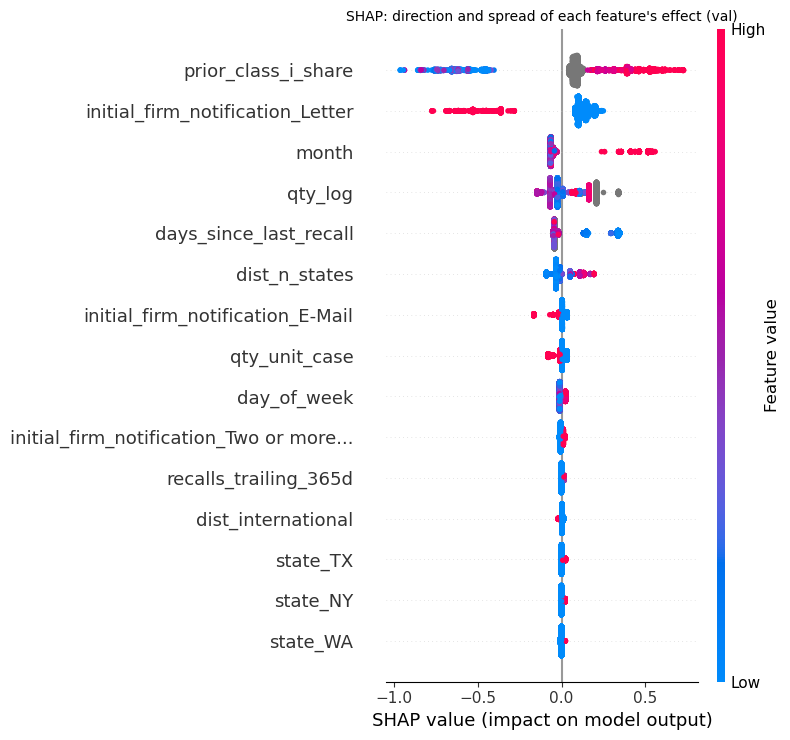

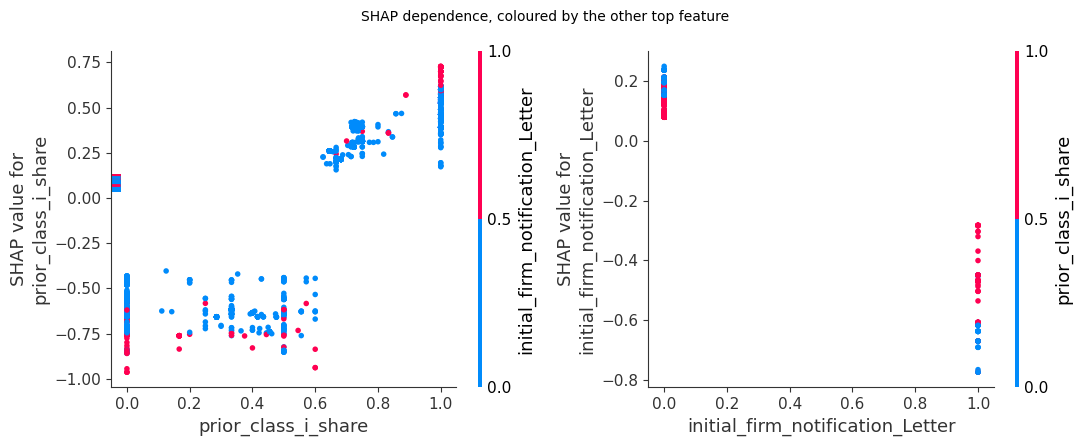


SHAP importance aggregated to the 17 source features, vs the Phase 2 verdict:
                             shap             phase2
prior_class_i_share        0.2669  REAL (replicates)
initial_firm_notification  0.1957       NEVER TESTED
month                      0.0990       NEVER TESTED
qty_log                    0.0942       NEVER TESTED
days_since_last_recall     0.0909       NEVER TESTED
dist_n_states              0.0508         train only
qty_unit                   0.0160       NEVER TESTED
day_of_week                0.0139         train only
state                      0.0089       NEVER TESTED
recalls_trailing_365d      0.0034       NEVER TESTED
dist_international         0.0029    not significant
qty_parseable              0.0000    not significant
country                    0.0000       NEVER TESTED
prior_recall_count         0.0000       NEVER TESTED
dist_single_state          0.0000    not significant
dist_nationwide            0.0000    not significant
voluntary_mandated  

In [ ]:
import shap, matplotlib.pyplot as plt

# The model inside the pipeline never sees FEATURES -- it sees the one-hot matrix the ColumnTransformer produced
pre_fit = tuned.named_steps["pre"]                      #pre_fit is the preprocessing step (ColumnTransformer) that transformed the input features (17 features) into a 89 columns format through one hot encoding, named_steps accesses the preprocessing step in the pipeline for individual features
Xva_t   = pd.DataFrame(pre_fit.transform(Xva),          #transforms old xval set with new pre_fit named_steps to pull each individual feature out for SHAP
                       columns=pre_fit.get_feature_names_out()).rename(
                       columns=lambda c: c.split("__", 1)[1])          # strip "num__"/"cat__" before column name (previously labeled by me)
print(f"matrix the booster sees: {len(Xva_t.columns)} columns from {len(FEATURES)} features due to one hot encoding")

expl = shap.TreeExplainer(tuned.named_steps["m"])  #TreeExplainer is a SHAP explainer for tree-based models (like XGBoost) that computes SHAP values efficiently for each feature in the model
sv   = expl.shap_values(Xva_t)                     # sv is the new shap values (89 columns as features), expected values output in LOG-ODDS units (XGBoost defaults)
print(f"shap values {sv.shape}   base value (mean log-odds) {expl.expected_value:.3f}")   #base value is the models output before looking at any features (in log odds), can be used as benchmark model

# mean |SHAP| = average size of a feature's push in log-odds. Not a direction, a magnitude.
imp = (pd.Series(np.abs(sv).mean(0), index=Xva_t.columns)   #.mean(0) gets rid of rows, and computes mean of SHAP values across each feature, giving a measure of feature importance in terms of its average contribution to the model's predictions. 
         .sort_values(ascending=False))
print("\ntop 15 by mean |SHAP| (log-odds):")
for k, v in imp.head(15).items():
    print(f"   {k:34s} {v:.4f}")
print(f"\n{(imp == 0).sum()} of {len(imp)} columns are never used by any tree.")

# shap calls plt.tight_layout() internally and warns when long category names do not fit.
# Cosmetic and not actionable from here, so it is filtered rather than left to look like a bug.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Tight layout not applied.*")      #ignore warning if message detected 
    short = [c if len(c) <= 40 else c[:37] + "..." for c in Xva_t.columns]   # one category name is 100+ characters and squeezes the plot
    plt.figure()
    shap.summary_plot(sv, Xva_t, max_display=15, show=False, feature_names=short)                      #Beeswarm chart tells us: direction (does a high prior_class_i_share push toward Class I or away?), and spread (the vertical scatter at a fixed feature value, which is the visual evidence for interactions cited in the verdict)
    plt.title("SHAP: direction and spread of each feature's effect (val)", fontsize=10)
    plt.tight_layout(); plt.savefig("fig_shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

# Colour is the value of the second feature (compared to a one-feature-at-a-time contrast). If the colour is random, the model is ignoring the second feature. If the colour is ordered, the model is using it. If the relationship between a feature and its SHAP value CHANGES SHAPE with the colour, the model is using the two together -- exactly what a one-feature-at-a-time contrast is blind to.
# If the relationship between a feature and its SHAP value CHANGES SHAPE with the colour, the model is using the two together (pushing one feature depends on the value of the other) 
top2 = imp.index[:2].tolist()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, f in zip(axes, top2):
    shap.dependence_plot(f, sv, Xva_t, interaction_index=top2[1] if f == top2[0] else top2[0],
                         ax=ax, show=False)
fig.suptitle("SHAP dependence, coloured by the other top feature", fontsize=10)
fig.tight_layout(); fig.savefig("fig_shap_dependence.png", dpi=150); plt.show()

# --- cross-check against Phase 2's inferential audit ---
#dictionary mapping each one-hot encoded column back to its original feature name (if the column name matches the feature name or starts with the feature name followed by an underscore, it maps to that feature; otherwise, it maps to itself)
src = {c: next((f for f in sorted(FEATURES, key=len, reverse=True)
                if c == f or c.startswith(f + "_")), c) for c in Xva_t.columns}     
by_feat = imp.groupby(src).sum().sort_values(ascending=False)
verdict = dict(zip(inf.feature, inf.verdict))            # from the Phase 2 signal audit
chk = pd.DataFrame({"shap": by_feat,
                    "phase2": [verdict.get(f, "NEVER TESTED") for f in by_feat.index]})
print("\nSHAP importance aggregated to the 17 source features, vs the Phase 2 verdict:")
print(chk.round(4).to_string())

# No magnitude thresholds here. "SHAP is exactly 0" is a fact (no tree ever split on the feature)
# Rank instead of threshold .
tested_zero = chk[(chk.phase2 == "not significant") & (chk.shap == 0)]
tested_ns   = chk[chk.phase2 == "not significant"]
never_top   = chk[chk.phase2 == "NEVER TESTED"].head(5)          # chk is sorted by SHAP
print(f"\nnever tested by Phase 2, top 5 by SHAP: {', '.join(never_top.index)}")
print(f"'not significant' in Phase 2 and exactly zero SHAP: {len(tested_zero)} of {len(tested_ns)} ({', '.join(tested_zero.index)})")
print(f"features with exactly zero SHAP: {(by_feat == 0).sum()} of {len(by_feat)}")

# --- claim 1: the zero-SHAP features really are droppable ---
DEAD = sorted(by_feat[by_feat == 0].index)
keep_num = [c for c in FEATURES_NUM if c not in DEAD]
keep_cat = [c for c in FEATURES_CAT if c not in DEAD]
lean = Pipeline([("pre", ColumnTransformer([
                    ("num", "passthrough", keep_num),       #include keep_num features unchanged 
                    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20,      #min_frequency=20 merges rare categories into one shared column (a lot of columns mainly 0 due to one hot encoding), handle_unknown="ignore" if a category appears in the validation set but not in the training set, it will be ignored 
                                          sparse_output=False), keep_cat)])),             #sparse_output=False outputs dense array (only those with 1, drops 0) to save memory space
                 ("m", xgb.XGBClassifier(eval_metric="logloss", random_state=42,
                                         n_jobs=1, **BEST_PARAMS))]).fit(Xtr[keep_num + keep_cat], ytr)
lean_ap = average_precision_score(yva, lean.predict_proba(Xva[keep_num + keep_cat])[:, 1])     #indexing two column probability output from predict_proba
old_ap = average_precision_score(yva, tuned.predict_proba(Xva)[:, 1])                         #original model with 17 features (instead of 11 from Xva[keep_num + keep_cat]), used to compare new model with less features
print(f"\n  dropping the {len(DEAD)} zero-SHAP features: val PR-AUC {old_ap:.4f} -> {lean_ap:.4f} "
      f"({lean_ap - old_ap:+.4f})")
print(f"     dropped: {', '.join(DEAD)}")  #ended up keeping the features anyways since the change is negligible and within noise, and the cost of removing them is not worth it

# --- claim 2: interactions are real ---
# If a feature acted alone, every row with the SAME feature value would get the SAME SHAP value. Spread at a fixed value is interaction (features interacting)
top = imp.index[0]
at1 = sv[:, Xva_t.columns.get_loc(top)][Xva_t[top] == Xva_t[top].max()]
print(f"\n  rows where {top} == {Xva_t[top].max():.2f} ({len(at1)} rows) get SHAP values")
print(f"     spanning {at1.min():+.3f} to {at1.max():+.3f} -- a spread of {at1.max()-at1.min():.3f}")

**Result.**

- **Beeswarm** (right = pushed toward Class I). A history of Class I recalls pushes toward
  Class I and a clean history pushes away; firms with no history (grey) get a slight push
  toward Class I. Notification by `Letter` pushes hard away from Class I, and later months push
  toward it.
- **Dependence plots.** `prior_class_i_share` acts as a step, not a slope: about −0.5 below 0.65
  and +0.4 above it. No history gets +0.08 while a clean history gets −0.6, a distinction
  imputation would have erased. At `Letter = 1`, repeat Class I offenders get a softer letter
  penalty (−0.3 vs −0.8), and the 737 rows with a share of exactly 1.0 still span +0.17 to +0.73.
  These interactions are real on validation but do not carry over to test.
- **Against the Phase 2 audit.** Phase 2 tested only 7 of the 17 features, and four of SHAP's
  top five (`initial_firm_notification`, `month`, `qty_log`, `days_since_last_recall`) were
  never tested. So the failed prediction came mostly from an incomplete audit, not from blind
  contrasts. Where Phase 2 said "not significant", three of four features get exactly zero SHAP,
  but that agreement is weak evidence: `dist_single_state` is just `dist_n_states == 1` and
  `qty_parseable` is just "`qty_log` is not missing", so the model never needs them.
- **Unused features.** 6 of 17 features get exactly zero SHAP. Dropping them moves validation
  PR-AUC by −0.27 points (0.6944 → 0.6917), within noise, so they are kept.

### Step 8: error analysis

Read the most confident mistakes at the short-list threshold (p ≥ 0.50), then test the patterns
they suggest with the same difference-of-proportions CIs as the signal audit.
`reason_for_recall` is shown as evidence only.

In [ ]:
# one metadata row per recall event, to attach to the event-level predictions
meta = (df[df["split"] == "val"]
        .groupby("event_id")
        .agg(recall_number=("recall_number", "first"),        #"first" skips nan and returns first non null value
             firm=("recalling_firm", "first"),
             date=("recall_initiation_date", "min"),           #min for the minimum date of recall initiation for an event
             n_products=("recall_number", "size"),
             pcs=("prior_class_i_share", "first"),
             prc=("prior_recall_count", "first"),
             dsl=("days_since_last_recall", "first"),
             ns=("dist_n_states", "first"),
             notif=("initial_firm_notification", "first"),
             reason=("reason_for_recall", "first")))

err = pred_va.set_index("e").join(meta)                                         #"e" = match by column e (event id)
err["flagged"] = err.p >= THRESHOLDS["high-precision (short list)"]                #flag high probability of class I for review
err["kind"] = np.select([(err.y == 1) & ~err.flagged, (err.y == 0) & err.flagged,           #NOT FLAGGED BUT CLASS I (FN), FLAGGED BUT NOT CLASS I (FP), FLAGGED & CLASS I(TP), else TN
                         (err.y == 1) & err.flagged],
                        ["FALSE NEGATIVE", "FALSE POSITIVE", "true positive"], "true negative")
print(err.kind.value_counts().to_string())

def show(kind, sort_col, asc, n=15):
    sub = err[err.kind == kind].sort_values(sort_col, ascending=asc).head(n)
    print(f"\n{'='*100}\n{kind}S -- the {n} most confident mistakes\n{'='*100}")
    for _, r in sub.iterrows():
        print(f"p={r.p:.3f}  {r.recall_number:12s} {str(r.date)[:10]}  "
              f"{r.n_products:3d} products  {str(r.firm)[:32]:32s}")
        print(f"         prior_class_I_share={'none' if pd.isna(r.pcs) else f'{r.pcs:.2f}'}"
              f"  prior_recalls={r.prc:.0f}  states={r.ns:.0f}  notif={str(r.notif)[:22]}")
        print(f"         reason: {' '.join(str(r.reason).split())[:150]}")

show("FALSE NEGATIVE", "p", True)     # Class I the model scored LOWEST -- the dangerous errors
show("FALSE POSITIVE", "p", False)    # non-Class I the model scored HIGHEST -- the wasted reviews

# The obvious hypothesis after reading the lists: the model fails on firms with no history because prior_class_i_share carries most of the signal and is null for them 
# Same machinery as the Phase 2 audit: two pre-specified groups, difference of proportions 95% CI.
from statsmodels.stats.proportion import confint_proportions_2indep
err["correct"] = err.kind.str.startswith("true")
nohist, hist = err[err.pcs.isna()], err[err.pcs.notna()]
#Accuracy Contrast CI
d, lo_hi = hist.correct.mean() - nohist.correct.mean(), confint_proportions_2indep(      #lo_hi holds lower and upper bound of the 95% CI (default alpha = 0.5)
    int(hist.correct.sum()), len(hist), int(nohist.correct.sum()), len(nohist),          #d stores difference between correct predictions for firms with prior class I and no prior class I recalls
    method="wald", compare="diff")
print(f"\n{'='*100}")
print(f"accuracy with firm history    {hist.correct.mean():.3f}  (n={len(hist)})")
print(f"accuracy with NO firm history/prior class I recalls {nohist.correct.mean():.3f}  (n={len(nohist)})")
print(f"difference {d:+.3f}  95% CI [{lo_hi[0]:+.3f}, {lo_hi[1]:+.3f}]  -> "
      f"{'REAL' if (lo_hi[0] > 0) == (lo_hi[1] > 0) else 'not significant'}")           #either both negative or both positive (if lower boundary is positive, upper boundary must be positive too hence the ==, vice versa for negatives)


pos = err[err.y == 1]                                      # recall/sensitivity, by history
ph, pn = pos[pos.pcs.notna()], pos[pos.pcs.isna()]
#Recall contrast CI
lo, hi = confint_proportions_2indep(int(ph.flagged.sum()), len(ph),
                                    int(pn.flagged.sum()), len(pn),
                                    method="wald", compare="diff")
print(f"\nrecall on Class I events WITH history    {ph.flagged.mean():.3f}  (n={len(ph)})")
print(f"recall on Class I events WITHOUT history {pn.flagged.mean():.3f}  (n={len(pn)})")
print(f"difference {ph.flagged.mean()-pn.flagged.mean():+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  -> "
      f"{'REAL' if (lo > 0) == (hi > 0) else 'not significant'}")
print(f"\nof {(err.kind=='FALSE NEGATIVE').sum()} false negatives, "
      f"{err[err.kind=='FALSE NEGATIVE'].pcs.isna().mean():.1%} have no firm history, against "
      f"{err.pcs.isna().mean():.1%} of the val set overall.")
# The 15 worst false negatives are ALL notification-by-letter. EASY to conclude the model treats Letter as a veto, so measure it instead of asserting it.
LET = err.notif == "Letter"
print(f"  letters are genuinely lower risk: Class I rate {err[LET].y.mean():.3f} (n={LET.sum()}) "
      f"vs {err[~LET].y.mean():.3f} (n={(~LET).sum()})")
print(f"  recall on the exceptions: {err[LET & (err.y==1)].flagged.mean():.1%} of Class I letters "
      f"get flagged against {err[~LET & (err.y==1)].flagged.mean():.1%} of Class I non-letters.")

# Counting a few unambiguous hazard words in reason_for_recall to the hazard regex. This is not a model, its just an estimate of how much information the structured fields are leaving on the table.
HAZARD = r"listeria|salmonella|e\. ?coli|botul|undeclared|allergen|milk|peanut|lethal|death"
err["hazard_word"] = err.reason.fillna("").str.contains(HAZARD, case=False, regex=True)     #new column that prints T/F if reason text matches hazard regex (false otherwise, replace missing text with empty string so rows can still be searched)
print(f"\nreason_for_recall contains an obvious hazard word:")
print(err.groupby("y")["hazard_word"].agg(["mean", "size"]).round(3).to_string())
a, b = err[err.hazard_word], err[~err.hazard_word]
lo, hi = confint_proportions_2indep(int(a.y.sum()), len(a), int(b.y.sum()), len(b),
                                    method="wald", compare="diff")
print(f"Class I rate: hazard word {a.y.mean():.3f} vs no hazard word {b.y.mean():.3f}  "
      f"diff {a.y.mean()-b.y.mean():+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")

kind
true negative     768
FALSE NEGATIVE    322
true positive     154
FALSE POSITIVE    116

FALSE NEGATIVES -- the 15 most confident mistakes
p=0.129  F-0975-2021  2021-05-13    1 products  Organic By Nature, Inc.         
         prior_class_I_share=0.00  prior_recalls=1  states=0  notif=Letter
         reason: Product recalled due to undeclared milk in MCT powder used in manufacturing. Milk is not declared on the label. Product item #'s 4600-P65, 4600
p=0.129  F-0960-2020  2020-05-01    1 products  Mondelez Global Llc             
         prior_class_I_share=0.17  prior_recalls=6  states=0  notif=Letter
         reason: The firm is recalling a limited quantity of RITZ Cheese Cracker Sandwiches Family Size (21.6 oz. carton) product in the United States, because of unde
p=0.130  F-0632-2021  2021-05-07    1 products  SARA LEE FROZEN FOODS           
         prior_class_I_share=0.00  prior_recalls=1  states=0  notif=Letter
         reason: Potentially undeclared peanut
p=0.155  F-0

**Result.**

- **No firm history, no recall.** Overall accuracy barely differs with and without history,
  because missing history pushes predictions toward the middle and creates both kinds of error.
  Recall is what collapses: **0.545** on Class I events with history vs **0.130** without
  (+0.415, CI +0.338 to +0.493). 69% of false negatives have no history, against 57% of all
  validation events.
- **The `Letter` prior is right on average but applied too hard.** All 15 of the most confident
  false negatives were notified by letter. Letters really are lower risk (22.4% Class I vs
  37.0%), but only 19.5% of Class I letter recalls get flagged, against 33.6% of other Class I
  recalls. It is not a veto, and the worst-15 list is a selected tail.
- **The hazard is in the text.** A 10-word hazard regex over `reason_for_recall` separates
  Class I by **+0.461** (CI +0.421 to +0.502), more than any structured feature (+0.33 / +0.39).
  **Caveat:** the word list was written after reading these false negatives on the same
  validation set, so +0.461 is optimistic: an order of magnitude, not a result. Part 2 has to
  learn the vocabulary on train and test it on unseen years.

### Step 9: the test set, opened once

Everything above used train and validation only. Three models are scored on 2022+: logistic
regression and XGBoost refit on train+val, plus the train-only XGBoost, because the step 5
thresholds are on its probability scale. Ranking metrics belong to the refits; threshold
metrics belong to the train-only model.

In [22]:
# clone() gives each refit an unfitted copy of the preprocessor. Reusing tree_pre itself would
# refit the transformer `tuned` already uses (89 one-hot columns become 91, and predict_proba fails).
from sklearn.base import clone
Xall2, yall2 = pd.concat([Xtr, Xva]), np.concatenate([ytr, yva])
final_all = Pipeline([("pre", clone(tree_pre)),
                      ("m", xgb.XGBClassifier(eval_metric="logloss", random_state=42,
                                              n_jobs=1, **BEST_PARAMS))]).fit(Xall2, yall2)
lr_all    = Pipeline([("pre", clone(lr_pre)),
                      ("m", LogisticRegression(max_iter=2000))]).fit(Xall2, yall2)

pred_te      = event_frame(tuned,     Xte, yte, ete)               #tuned model pipeline in cell above
pred_te_all  = event_frame(final_all, Xte, yte, ete)
pred_te_lr   = event_frame(lr_all,    Xte, yte, ete)                
BASE_TE = pred_te.y.mean()
print(f"test rows {len(Xte)}   test events {len(pred_te)}")
print(f"no-skill: rows {yte.mean():.4f}   test events {BASE_TE:.4f}   (val events were {BASE_VA:.3f})")

def scores(name, fitted, pe):
    p = fitted.predict_proba(Xte)[:, 1]
    return {"model": name,
            "test_pr_auc_row":   average_precision_score(yte, p),
            "test_roc_row":      roc_auc_score(yte, p),
            "test_pr_auc_event": average_precision_score(pe.y, pe.p),
            "test_roc_event":    roc_auc_score(pe.y, pe.p)}

final_tbl = pd.DataFrame([
    {"model": "no-skill (base rate)", "test_pr_auc_row": yte.mean(), "test_roc_row": 0.5,       #roc symmetry (TP/TP+FN) cancels out making base always 0.5, precision (TP/TP+FP) shuffles randomly
     "test_pr_auc_event": BASE_TE, "test_roc_event": 0.5},
    scores("logistic regression (train+val)", lr_all,    pred_te_lr),
    scores("xgboost tuned (train only)",      tuned,     pred_te),
    scores("xgboost tuned (train+val)",       final_all, pred_te_all)]).set_index("model")
print()
print("=" * 88)
print("TEST RESULTS")
print("=" * 88)
print(final_tbl.round(4).to_string())


test rows 7336   test events 2230
no-skill: rows 0.4625   test events 0.3722   (val events were 0.350)

TEST RESULTS
                                 test_pr_auc_row  test_roc_row  test_pr_auc_event  test_roc_event
model                                                                                            
no-skill (base rate)                      0.4625        0.5000             0.3722          0.5000
logistic regression (train+val)           0.6261        0.6295             0.4786          0.6001
xgboost tuned (train only)                0.6022        0.6107             0.4658          0.5898
xgboost tuned (train+val)                 0.5751        0.5899             0.4609          0.5830


Is the gap between XGBoost and logistic regression real? A paired bootstrap over test **events**
(2,000 resamples) gives its 95% CI. The cell then applies the step 5 thresholds unchanged,
scores the probabilities, and compares validation with test.

In [20]:
rng = np.random.default_rng(42)                    #random generator seeded for reproducibility 
n   = len(pred_te_all)
d   = np.empty(2000)                               #2000 bootstrap differences (one per sample), reserves the memory
for i in range(2000):
    idx  = rng.integers(0, n, n)                     #draw same number of events from test set (n) with replacement
    y_b  = pred_te_all.y.values[idx]
    if y_b.min() == y_b.max():                       # degenerate if only 1 class in the resample
        d[i] = np.nan; continue
    d[i] = (average_precision_score(y_b, pred_te_all.p.values[idx])
            - average_precision_score(y_b, pred_te_lr.p.values[idx]))
lo, hi = np.nanpercentile(d, [2.5, 97.5])
obs = (final_tbl.loc["xgboost tuned (train+val)", "test_pr_auc_event"]
       - final_tbl.loc["logistic regression (train+val)", "test_pr_auc_event"])
print()
print(f"event-level PR-AUC, XGBoost - logistic regression = {obs:+.4f}")
print(f"   bootstrap 95% CI [{lo:+.4f}, {hi:+.4f}]  ({np.nanmean(d < 0):.1%} of resamples favour LR)")                    #nanmean ignores nan values when finding the mean, d<0 specifies mean when logistic regression scored higher than XGboost 
print(f"   -> {'REAL: the gap excludes zero' if (lo > 0) == (hi > 0) else 'NOT significant: the gap could be zero'}")

# --- the pre-committed operating points, on the train-only model ---
print()
print("=" * 88)
print("OPERATING POINTS (thresholds fixed on val in step 5, applied unchanged)")
print("=" * 88)
op_te = pd.DataFrame([at_threshold(pred_te, t) for t in THRESHOLDS.values()],
                     index=[f"{k}  p>={v:.4f}" for k, v in THRESHOLDS.items()])
print(op_te[["flagged", "flag_rate", "precision", "prec_lo", "prec_hi", "lift",
             "recall", "rec_lo", "rec_hi", "f1"]].round(3).to_string())
print()
for k, t in THRESHOLDS.items():
    v, s = at_threshold(pred_va, t), at_threshold(pred_te, t)
    print(f"{k:30s} recall {v['recall']:.3f} (val) -> {s['recall']:.3f} (test)   "
          f"lift {v['lift']:.2f}x -> {s['lift']:.2f}x")
print()
print("Threshold transfer to the train+val refit (same thresholds, different probability scale):")
print(pd.DataFrame([at_threshold(pred_te_all, t) for t in THRESHOLDS.values()],
                   index=list(THRESHOLDS))[["flag_rate", "precision", "lift", "recall"]]
        .round(3).to_string())

# --- do the probabilities mean anything on test? (step 6, extended) ---
b_x = brier_score_loss(yte, final_all.predict_proba(Xte)[:, 1])
b_l = brier_score_loss(yte, lr_all.predict_proba(Xte)[:, 1])
b_c = brier_score_loss(yte, np.full(len(yte), yall2.mean()))
print()
print(f"Brier on test: xgboost {b_x:.4f}   logistic {b_l:.4f}   base-rate constant {b_c:.4f}")

# --- val -> test drift, stated plainly ---
print()
print("=" * 88)
print("VAL -> TEST")
print("=" * 88)
drift = pd.DataFrame({
    "val":  {"pr_auc_row": results["4. xgboost (tuned)"]["val_pr_auc"],
             "pr_auc_event": results["4. xgboost (tuned)"]["val_pr_auc_event"],
             "no_skill_event": BASE_VA},
    "test": {"pr_auc_row": final_tbl.loc["xgboost tuned (train+val)", "test_pr_auc_row"],
             "pr_auc_event": final_tbl.loc["xgboost tuned (train+val)", "test_pr_auc_event"],
             "no_skill_event": BASE_TE}})
drift["change"] = drift.test - drift.val
print(drift.round(4).to_string())
print()
for lab, ap, b in [("val", drift.loc["pr_auc_event", "val"], BASE_VA),
                   ("test", drift.loc["pr_auc_event", "test"], BASE_TE)]:
    print(f"   {lab:5s} event PR-AUC {ap:.4f} / no-skill {b:.4f} = {ap/b:.2f}x")
# ============================== the verdict ==============================
gap_va = (results["4. xgboost (tuned)"]["val_pr_auc"]
          - results["1. logistic regression"]["val_pr_auc"])
gap_te = (final_tbl.loc["xgboost tuned (train+val)", "test_pr_auc_row"]
          - final_tbl.loc["logistic regression (train+val)", "test_pr_auc_row"])
print()
print("=" * 88)
print("VERDICT -- spec section 9 kill criterion, re-run on test")
print("=" * 88)
print(f"   row-level gap, XGBoost - logistic regression:  val {gap_va:+.4f}   test {gap_te:+.4f}")
print(f"   kill criterion (gain < 3 points): {'TRIGGERED on test' if gap_te < 0.03 else 'not triggered'}")


event-level PR-AUC, XGBoost - logistic regression = -0.0178
   bootstrap 95% CI [-0.0403, +0.0038]  (94.8% of resamples favour LR)
   -> NOT significant: the gap could be zero

OPERATING POINTS (thresholds fixed on val in step 5, applied unchanged)
                                        flagged  flag_rate  precision  prec_lo  prec_hi   lift  recall  rec_lo  rec_hi     f1
high-recall (safety screen)  p>=0.4099     1491      0.669      0.404    0.380    0.430  1.087   0.727   0.695   0.756  0.520
high-precision (short list)  p>=0.5000      319      0.143      0.527    0.472    0.581  1.415   0.202   0.176   0.231  0.292

high-recall (safety screen)    recall 0.811 (val) -> 0.727 (test)   lift 1.18x -> 1.09x
high-precision (short list)    recall 0.324 (val) -> 0.202 (test)   lift 1.63x -> 1.41x

Threshold transfer to the train+val refit (same thresholds, different probability scale):
                             flag_rate  precision   lift  recall
high-recall (safety screen)      0.519 

# Phase 4 findings

**The headline is a negative result.** On the test set (2022+), tuned XGBoost is **not** better
than logistic regression: row-level PR-AUC 0.575 vs 0.626, event-level 0.461 vs 0.479. The
bootstrap 95% CI on the event-level difference is **[−0.040, +0.004]**; it contains zero, and
95% of resamples favour logistic regression. The kill criterion, which did not fire on
validation (+12.9 points), **fires on test** (−5.1 points).

### Why the validation number was wrong

The search scored 222 candidates against **one** validation fold of 1,360 events.
`PredefinedSplit` stopped it from training on the future, but not from overfitting the single
fold it was given. The fix is **rolling-origin cross-validation**: several successive
train → validation cuts (2014–16 → 2017, 2014–17 → 2018, …), so the score being maximised is an
average over folds. It is a lesson for future models, applying it now
would mean re-tuning with knowledge of the test result.

- **The search was still moving.** The final grid winner sits on the edge of its grid for
  6 of the 8 swept parameters: `learning_rate`, `n_estimators`, `reg_alpha` and `gamma` at
  the lower edge, `subsample` and `colsample_bytree` at the upper edge. Grids built to
  bracket the best value did not bracket it.
- **The +12.9 came mostly from a few large recalls.** The search and the kill criterion
  used row-level PR-AUC, where a 330-product recall counts 330 times. Dropping the five
  largest validation recalls cuts the gap to +4.8 points. At event level the gap was only
  +2.7 points (0.519 vs 0.492 in the Phase 3 table). So by the event-level measure, the
  kill criterion had already fired on validation.

### The scoreboard

| | val event PR-AUC | test event PR-AUC | stability |
|---|---|---|---|
| no-skill | 0.350 | 0.372 | — |
| logistic regression | 0.492 | 0.479 | −0.013 |
| xgboost (tuned) | 0.519 | 0.461 | −0.058 |

Logistic regression is both **competitive and more stable**. Because base rates differ between
periods, lift over each period's own no-skill line is the comparable number: **1.48× on
validation, 1.24× on test.**

### What held up

- The structured fields carry **real but modest** signal: both models clear no-skill on unseen
  years (event PR-AUC 0.479 and 0.461 against 0.372).
- The **short list** (`p ≥ 0.50`) keeps a **1.41× precision lift** on test while flagging 14%
  of recalls, with its CI above the base rate.
- `prior_class_i_share` replicates in Phase 2 and ranks first in SHAP.

### What did not

- **The interaction story.** The interactions SHAP shows on validation do not generalise, so
  Phase 2's prediction was right after all (step 7 shows why it looked wrong).
- **The safety screen.** On test it gives a 1.09× lift and misses its 80% recall target (72.7%).
- **Probabilities.** On test the Brier score is 0.2475 for XGBoost and 0.2514 for logistic
  regression, against 0.2512 for the constant: XGBoost edges it by 0.004 and logistic regression
  does not beat it. Both models are used as a **ranked queue with a fixed threshold**, never as
  quoted probabilities.
- **More data.** Refitting on train+val lowered test PR-AUC (0.602 → 0.575): hyperparameters
  chosen for a train-sized fit on one fold did not transfer to a larger fit.

### Where it fails, and the case for Part 2

The model is close to blind on first-time recallers (recall 0.130 vs 0.545 with history), and
57% of validation recalls have no history. Its worst misses read like *"Potentially undeclared
peanut"* or *"found Listeria monocytogenes in Enoki mushrooms"*: the hazard is stated plainly in
text the model cannot see, which is what Part 2 models.

### Known issue, left for Part 2 to fix

`prior_class_i_share` counts a firm's earlier recalls by **initiation** date, but an
earlier recall's class only exists once FDA classifies it, a median 38 days later. Among
events with firm history, the share used at least one classification FDA had not made yet
in **20.4%** of train, **7.6%** of val and **6.2%** of test events (about 2% of all test
events). 

Both models use the feature, so both test scores are slightly optimistic. Part 2 will fix it if it reuses firm history, by counting only earlier
recalls FDA had already classified. The test set is now spent. Any further modelling change would be made with knowledge of these
numbers.
